#  Bank Marketing Campaign Response Prediction

##  Project Overview

This project focuses on building an end-to-end Machine Learning classification system
to predict whether a bank customer will subscribe to a term deposit after a marketing campaign.

###  Problem Type
Binary Classification

###  Domain
Banking & Marketing

###  Main Objective
Predict the likelihood of a customer subscribing to a term deposit based on
customer information and marketing campaign characteristics.

###  Dataset
UCI Bank Marketing Dataset

###  Machine Learning Approach
- Exploratory Data Analysis (EDA)
- Data Cleaning
- Feature Engineering
- Data Preprocessing
- Baseline Modeling
- Multiple Classification Models
- Cross Validation
- Hyperparameter Tuning
- Model Evaluation
- Feature Importance
- SHAP Explainability
- Error Analysis

###  Important Consideration
The project will prioritize reliable and realistic model performance while avoiding
data leakage and overfitting.

Accuracy will be considered alongside Precision, Recall, F1-Score, ROC-AUC,
and PR-AUC.

# Project Environment & Library Imports

In [ ]:
# Import Required Libraries

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    RandomizedSearchCV
)

from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier
)

# Reproducibility

RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

# Visualization Settings

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")
print(f"Random state: {RANDOM_STATE}")

Libraries imported successfully.
Random state: 42


# Data Acquisition & Loading

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving bank-full.csv to bank-full.csv


In [ ]:
# Load the raw dataset
df = pd.read_csv("../data/bank-full.csv", sep=";")

print("Dataset loaded successfully.")
print(f"Dataset shape: {df.shape}")

Dataset loaded successfully.
Dataset shape: (45211, 17)


In [ ]:
# Display the first five records
df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [ ]:
df.shape

(45211, 17)

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,45211.0,40.936210,10.618762,18.0,33.0,39.0,48.0,95.0
balance,45211.0,1362.272058,3044.765829,-8019.0,72.0,448.0,1428.0,102127.0
day,45211.0,15.806419,8.322476,1.0,8.0,16.0,21.0,31.0
duration,45211.0,258.163080,257.527812,0.0,103.0,180.0,319.0,4918.0
campaign,45211.0,2.763841,3.098021,1.0,1.0,2.0,3.0,63.0
pdays,45211.0,40.197828,100.128746,-1.0,-1.0,-1.0,-1.0,871.0
previous,45211.0,0.580323,2.303441,0.0,0.0,0.0,0.0,275.0


In [ ]:
df.describe(include="object").T

,count,unique,top,freq
job,45211,12,blue-collar,9732
marital,45211,3,married,27214
education,45211,4,secondary,23202
default,45211,2,no,44396
housing,45211,2,yes,25130
loan,45211,2,no,37967
contact,45211,3,cellular,29285
month,45211,12,may,13766
poutcome,45211,4,unknown,36959
y,45211,2,no,39922


In [ ]:
# Count missing values in each column
missing_values = df.isnull().sum()

# Display only columns containing missing values
missing_values[missing_values > 0]

,0


In [ ]:
# Identify categorical columns
categorical_columns = df.select_dtypes(include="object").columns

# Count "unknown" values in each categorical feature
unknown_counts = (
    df[categorical_columns]
    .apply(lambda column: (column == "unknown").sum())
    .sort_values(ascending=False)
)

# Calculate the percentage of unknown values
unknown_summary = pd.DataFrame({
    "Unknown Count": unknown_counts,
    "Unknown Percentage": (unknown_counts / len(df) * 100).round(2)
})

unknown_summary

,Unknown Count,Unknown Percentage
poutcome,36959,81.75
contact,13020,28.80
education,1857,4.11
job,288,0.64
marital,0,0.00
default,0,0.00
loan,0,0.00
housing,0,0.00
month,0,0.00
y,0,0.00


In [ ]:
# Count completely duplicated rows
duplicate_count = df.duplicated().sum()

print(f"Number of duplicate rows: {duplicate_count:,}")

Number of duplicate rows: 0


In [ ]:
# Calculate target class distribution
target_counts = df["y"].value_counts()
target_percentages = df["y"].value_counts(normalize=True) * 100

target_distribution = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages.round(2)
})

target_distribution

,Count,Percentage
y,,
no,39922,88.3
yes,5289,11.7


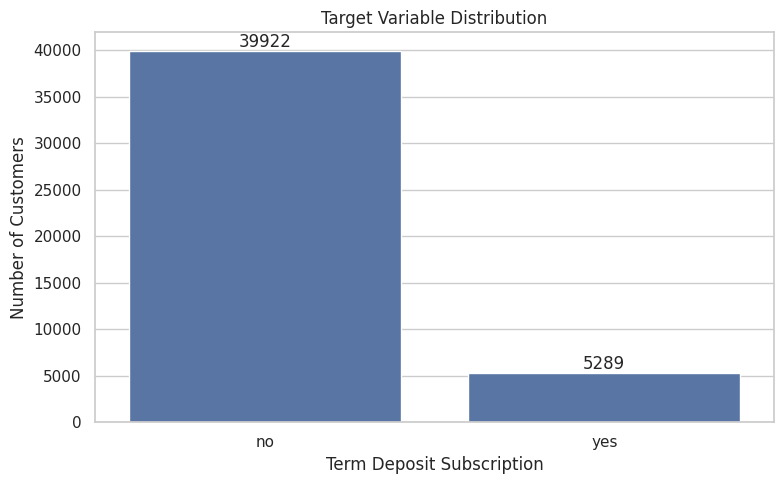

In [ ]:
# Visualize target distribution
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="y",
    order=df["y"].value_counts().index
)

plt.title("Target Variable Distribution")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

# Add count labels
for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

In [ ]:
# Identify numerical features
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

print("Numerical features:")
print(numerical_columns)

Numerical features:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


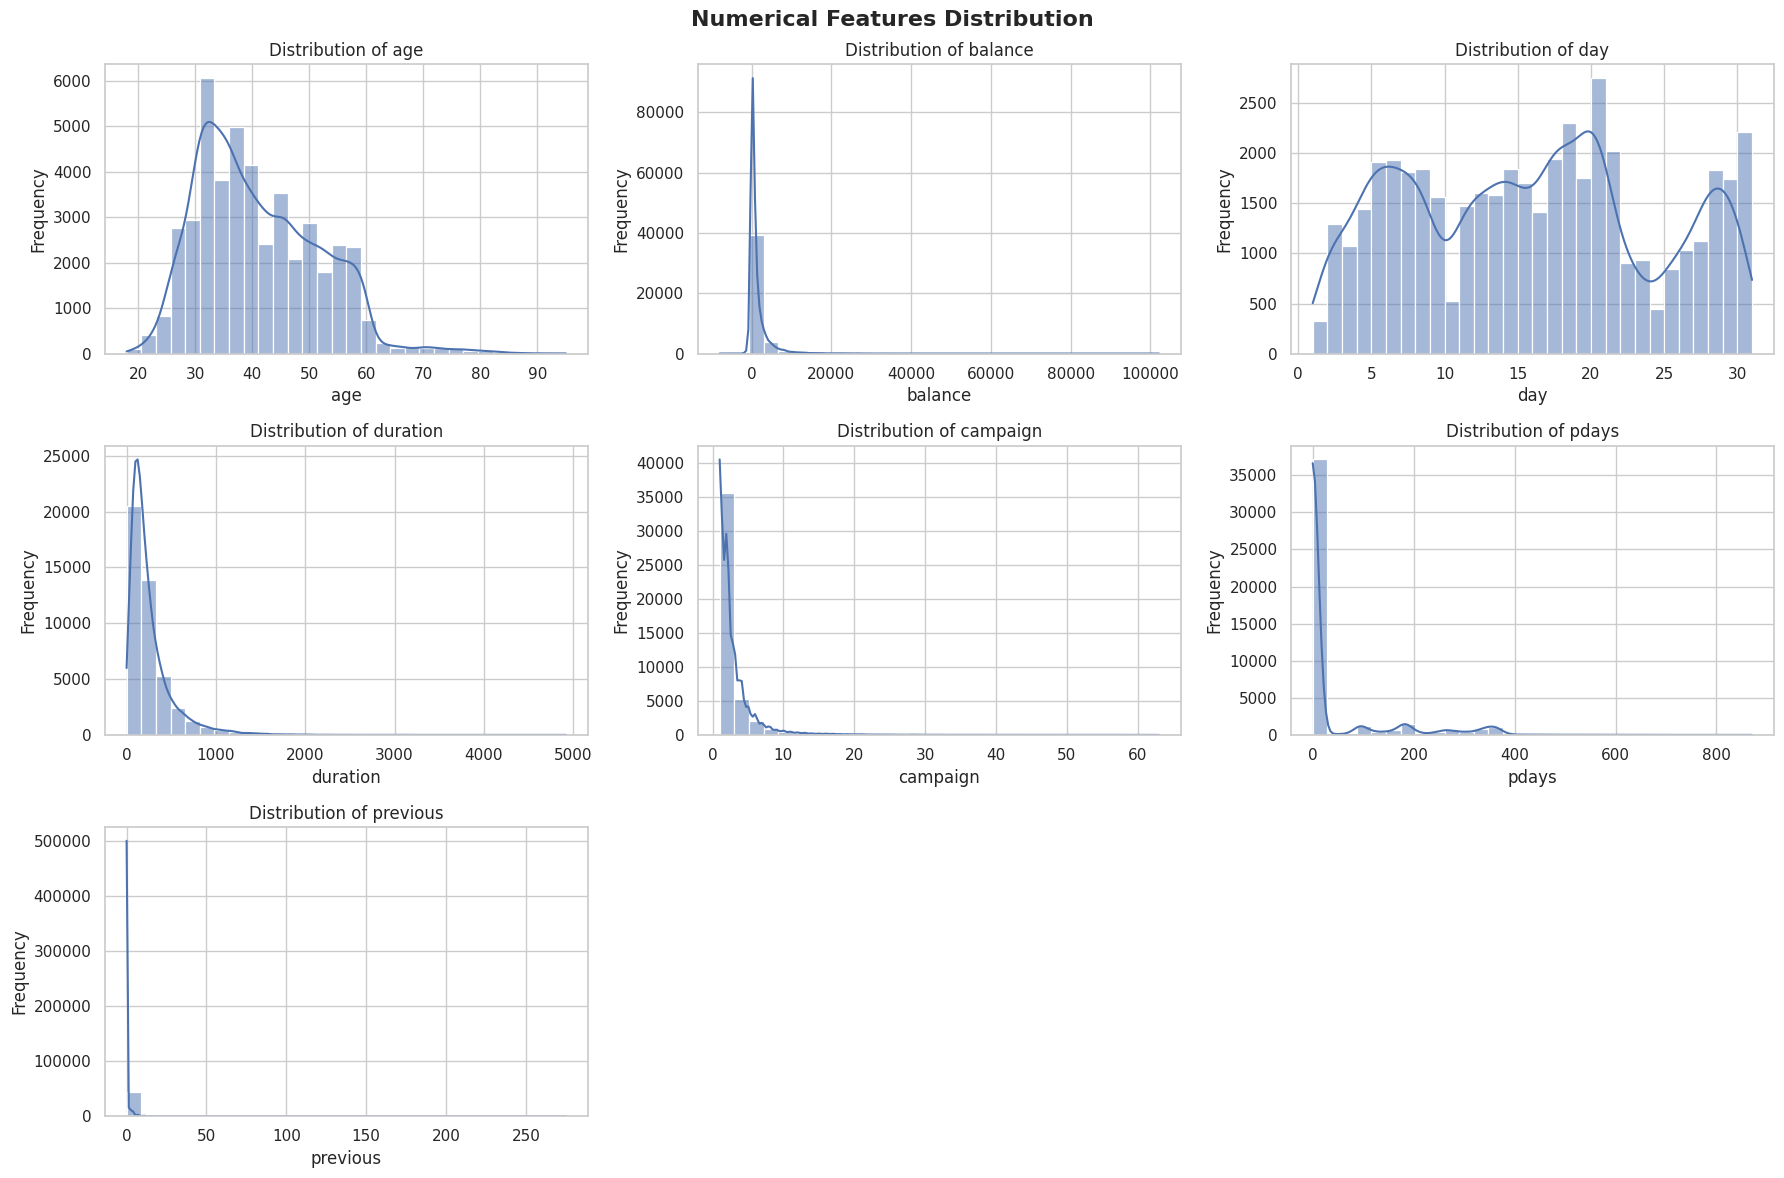

In [ ]:
# Plot numerical feature distributions in a grid

n_cols = 3
n_rows = int(np.ceil(len(numerical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 12)
)

axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.histplot(
        data=df,
        x=column,
        kde=True,
        bins=30,
        ax=axes[i]
    )

    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Frequency")

# Hide unused subplots
for i in range(len(numerical_columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle(
    "Numerical Features Distribution",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

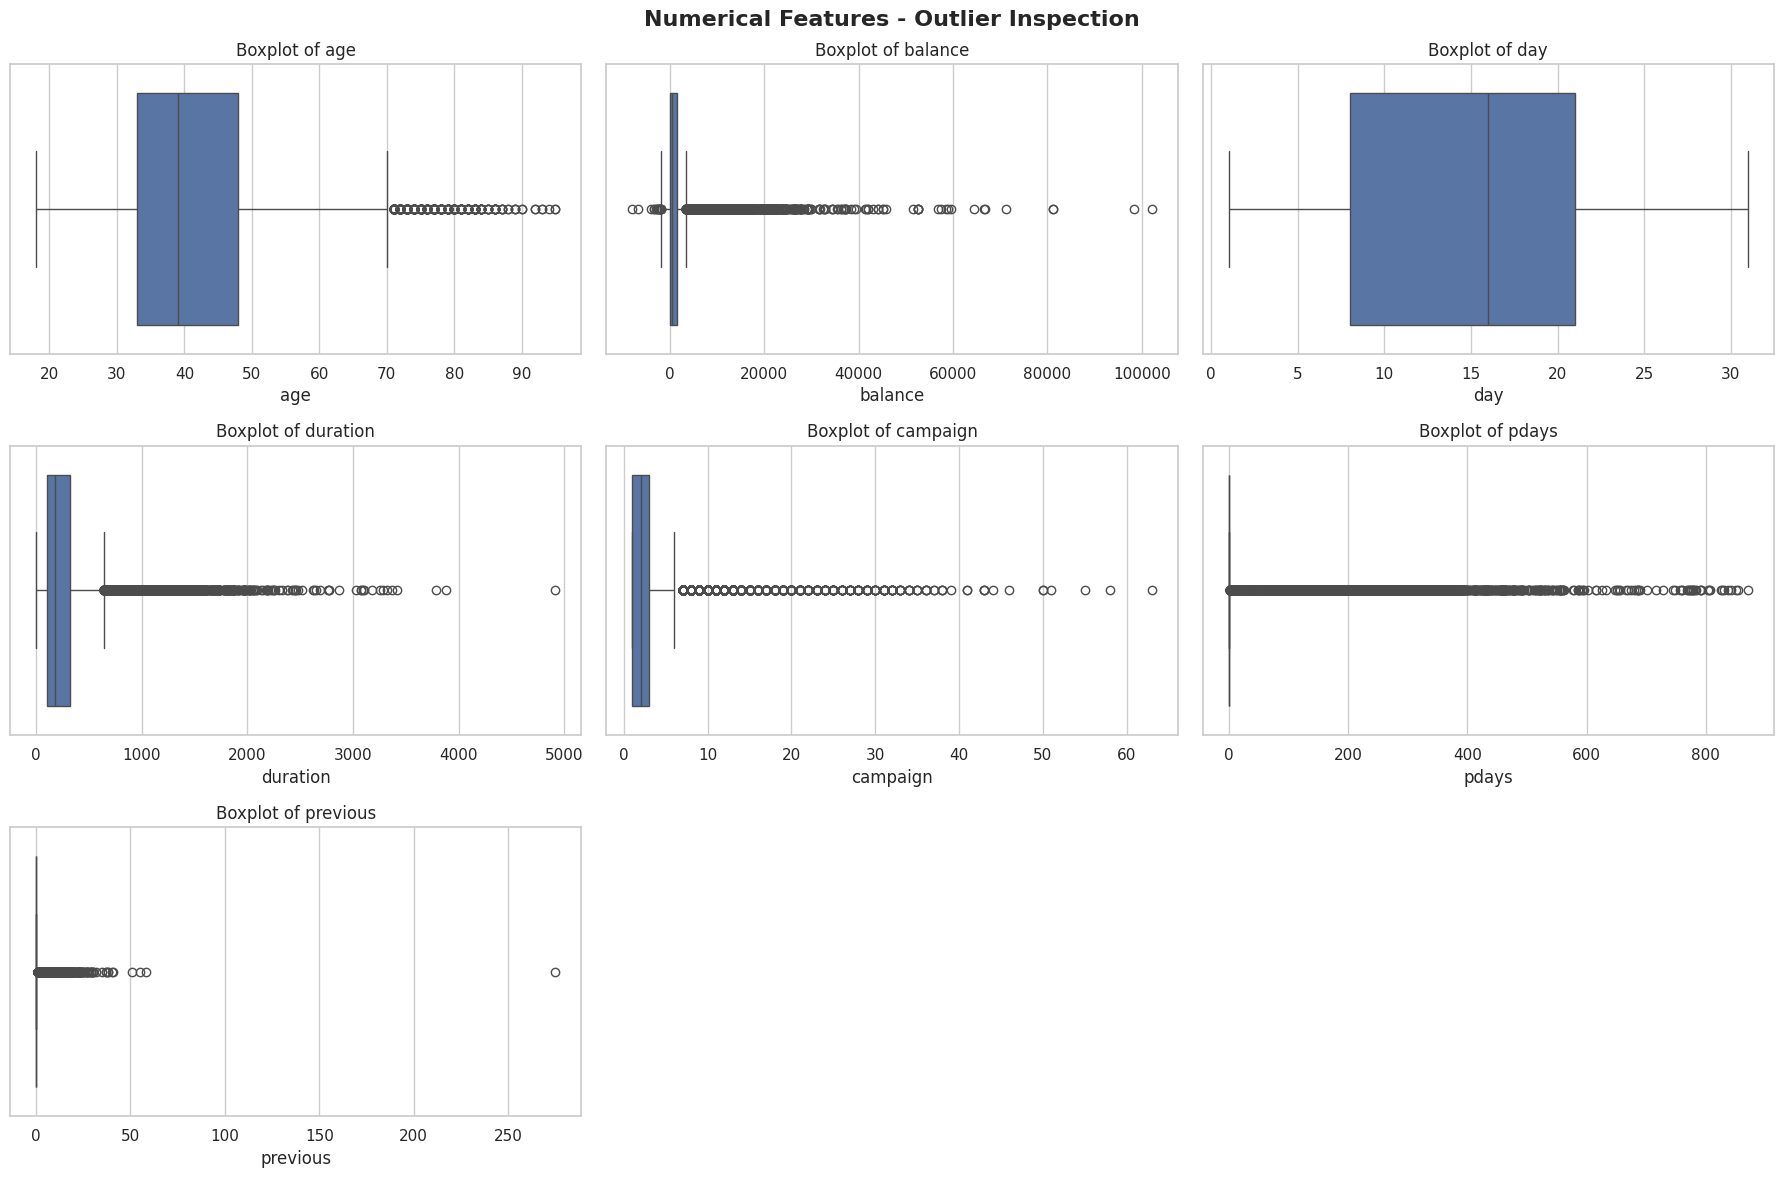

In [ ]:
# Create boxplots for numerical features

n_cols = 3
n_rows = int(np.ceil(len(numerical_columns) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, 12)
)

axes = axes.flatten()

for i, column in enumerate(numerical_columns):
    sns.boxplot(
        data=df,
        x=column,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot of {column}")
    axes[i].set_xlabel(column)

# Hide unused subplots
for i in range(len(numerical_columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle(
    "Numerical Features - Outlier Inspection",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

Outliers were investigated using distribution plots and IQR-based boxplots. No observations were removed solely based on statistical outlier detection, as extreme values may represent valid customer behavior.

In [ ]:
# Identify categorical features excluding the target variable
categorical_features = [
    column for column in categorical_columns
    if column != "y"
]

print("Categorical features:")
print(categorical_features)

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [ ]:
# Calculate customer count and subscription rate by job
job_analysis = (
    df.groupby("job")["y"]
    .agg(
        customer_count="count",
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .sort_values("subscription_rate", ascending=False)
)

job_analysis

,customer_count,subscription_rate
job,,
student,938,28.678038
retired,2264,22.791519
unemployed,1303,15.502686
management,9458,13.755551
admin.,5171,12.202669
self-employed,1579,11.842939
unknown,288,11.805556
technician,7597,11.056996
services,4154,8.883004


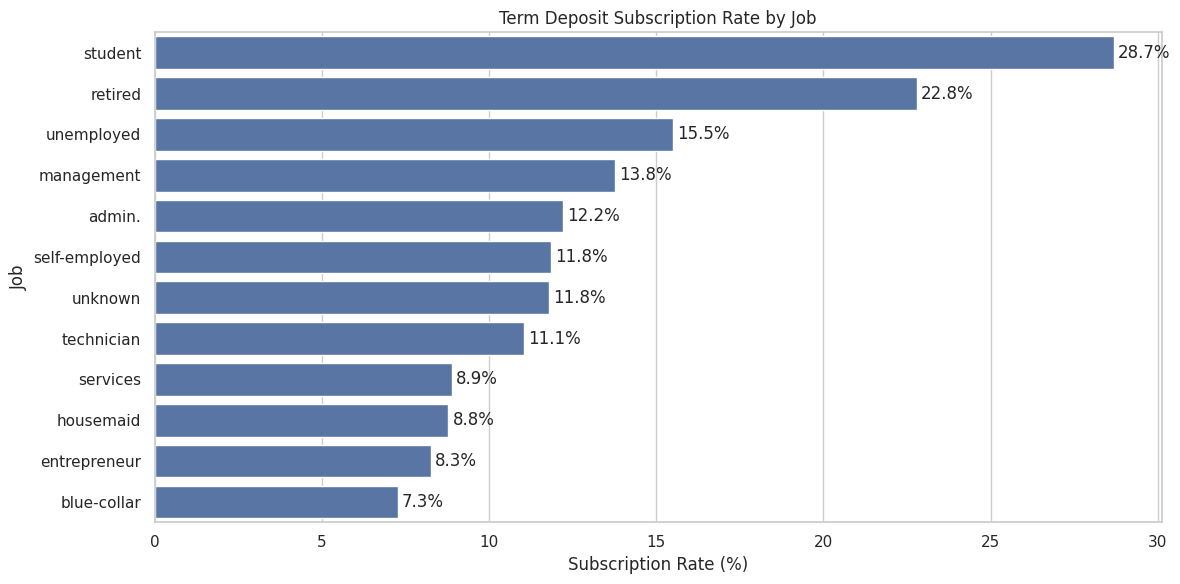

In [ ]:
# Visualize subscription rate by job
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=job_analysis.reset_index(),
    x="subscription_rate",
    y="job",
    order=job_analysis.index
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Job")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

In [ ]:
# Analyze subscription rate by previous campaign outcome

poutcome_analysis = (
    df.groupby("poutcome")["y"]
    .agg(
        customer_count="count",
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .sort_values("subscription_rate", ascending=False)
)

poutcome_analysis

,customer_count,subscription_rate
poutcome,,
success,1511,64.725347
other,1840,16.684783
failure,4901,12.609671
unknown,36959,9.161503


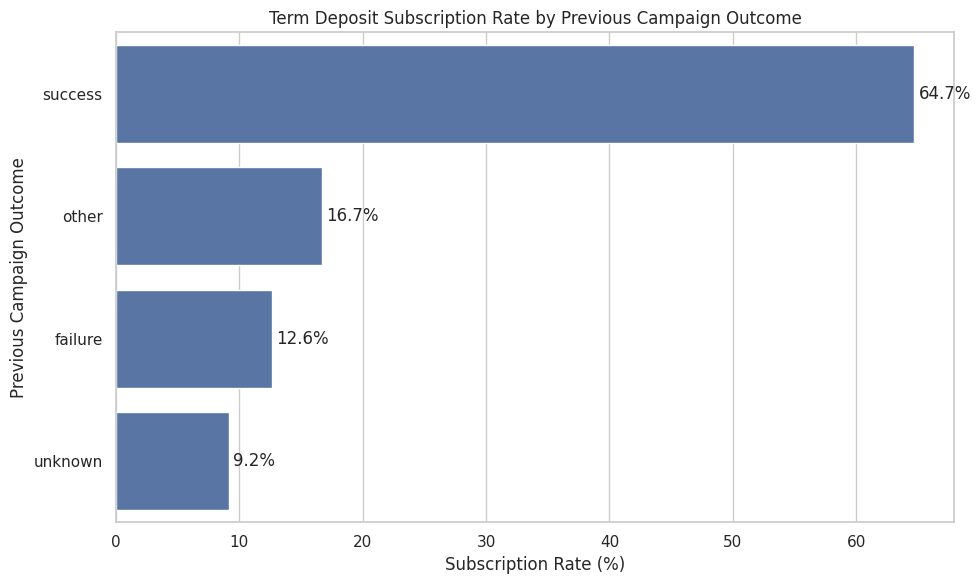

In [ ]:
# Visualize subscription rate by previous campaign outcome

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=poutcome_analysis.reset_index(),
    x="subscription_rate",
    y="poutcome",
    order=poutcome_analysis.index
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Previous Campaign Outcome")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

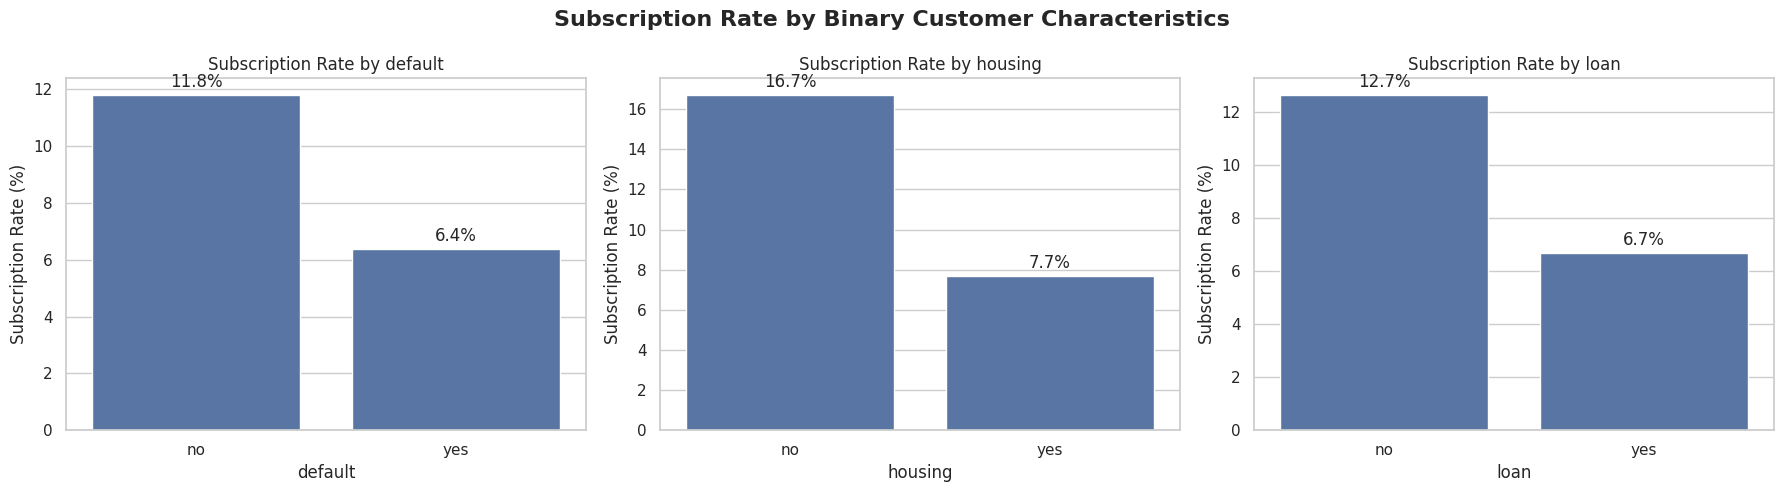

In [ ]:
# Binary categorical features to analyze
binary_features = ["default", "housing", "loan"]

# Create a 1x3 subplot layout
fig, axes = plt.subplots(
    1,
    len(binary_features),
    figsize=(18, 5)
)

for i, feature in enumerate(binary_features):

    # Calculate subscription rate
    analysis = (
        df.groupby(feature)["y"]
        .apply(lambda x: (x == "yes").mean() * 100)
        .sort_values(ascending=False)
    )

    sns.barplot(
        x=analysis.index,
        y=analysis.values,
        ax=axes[i]
    )

    axes[i].set_title(f"Subscription Rate by {feature}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Subscription Rate (%)")

    # Add percentage labels
    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt="%.1f%%",
            padding=3
        )

plt.suptitle(
    "Subscription Rate by Binary Customer Characteristics",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Analyze subscription rate by contact method

contact_analysis = (
    df.groupby("contact")["y"]
    .agg(
        customer_count="count",
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
    .sort_values("subscription_rate", ascending=False)
)

contact_analysis

,customer_count,subscription_rate
contact,,
cellular,29285,14.918900
telephone,2906,13.420509
unknown,13020,4.070661


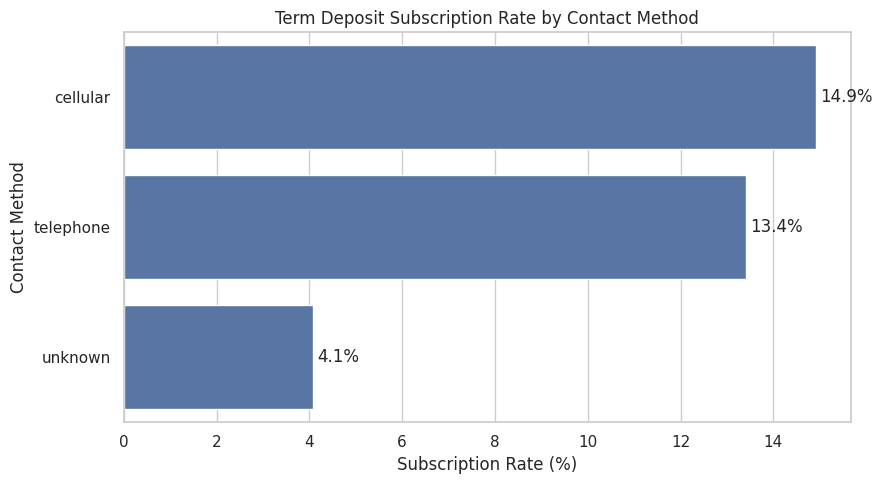

In [ ]:
# Visualize subscription rate by contact method

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=contact_analysis.reset_index(),
    x="subscription_rate",
    y="contact",
    order=contact_analysis.index
)

plt.title("Term Deposit Subscription Rate by Contact Method")
plt.xlabel("Subscription Rate (%)")
plt.ylabel("Contact Method")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

Customers contacted through cellular or telephone channels showed substantially higher subscription rates than customers with an unknown contact method.

In [ ]:
# Analyze subscription rate by campaign month

month_analysis = (
    df.groupby("month")["y"]
    .agg(
        customer_count="count",
        subscription_rate=lambda x: (x == "yes").mean() * 100
    )
)

# Sort months chronologically
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

month_analysis = month_analysis.reindex(month_order)

month_analysis

,customer_count,subscription_rate
month,,
jan,1403,10.121169
feb,2649,16.647792
mar,477,51.991614
apr,2932,19.679400
may,13766,6.719454
jun,5341,10.222805
jul,6895,9.093546
aug,6247,11.013286
sep,579,46.459413


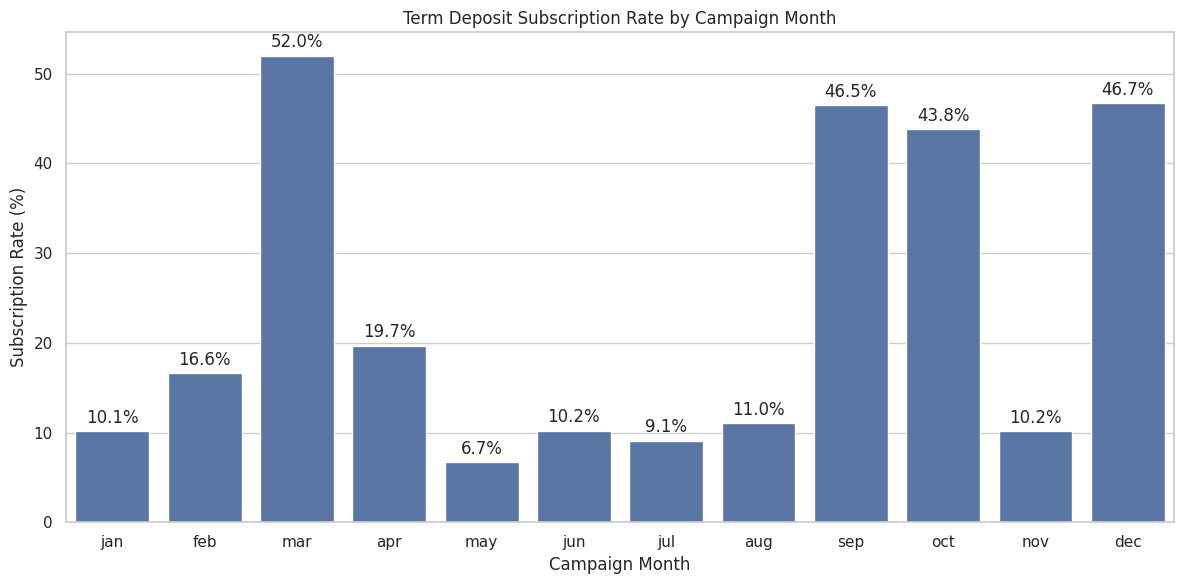

In [ ]:
# Visualize subscription rate by month

plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=month_analysis.reset_index(),
    x="month",
    y="subscription_rate",
    order=month_order
)

plt.title("Term Deposit Subscription Rate by Campaign Month")
plt.xlabel("Campaign Month")
plt.ylabel("Subscription Rate (%)")

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f%%",
        padding=3
    )

plt.tight_layout()
plt.show()

Because the sample size differs substantially across categories. A high conversion rate in a small group may be less reliable than a slightly lower rate observed across thousands of customers.

In [ ]:
# Compare numerical features across target classes

numerical_by_target = (
    df.groupby("y")[numerical_columns]
    .agg(["mean", "median"])
    .T
)

numerical_by_target

y                         no          yes
age      mean      40.838986    41.670070
         median    39.000000    38.000000
balance  mean    1303.714969  1804.267915
         median   417.000000   733.000000
day      mean      15.892290    15.158253
         median    16.000000    15.000000
duration mean     221.182806   537.294574
         median   164.000000   426.000000
campaign mean       2.846350     2.141047
         median     2.000000     2.000000
pdays    mean      36.421372    68.702968
         median    -1.000000    -1.000000
previous mean       0.502154     1.170354
         median     0.000000     0.000000

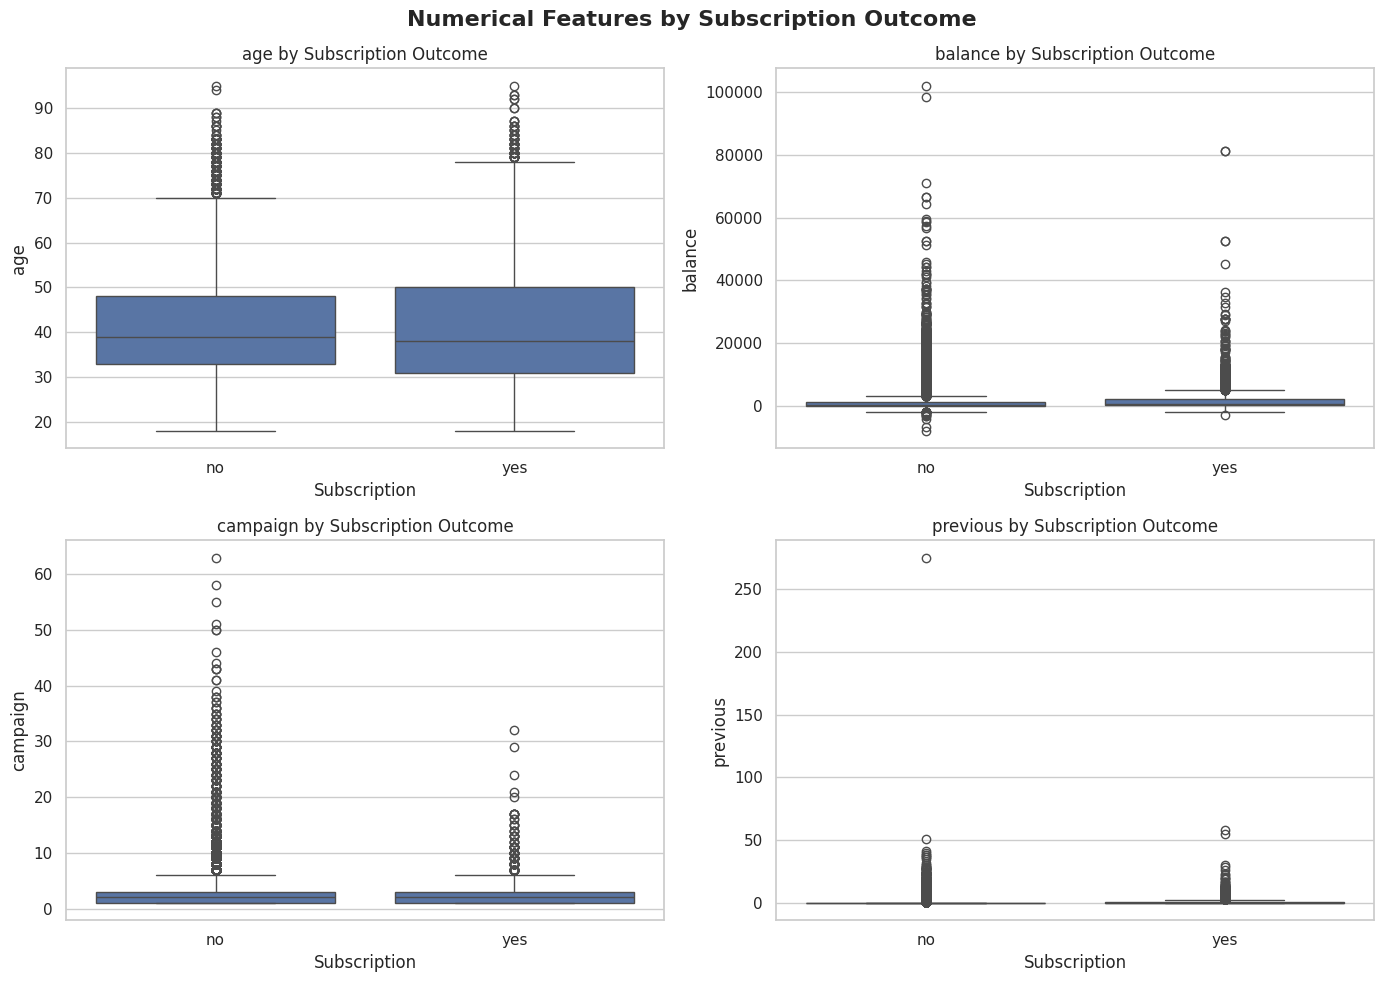

In [ ]:
# Create boxplots comparing numerical features by target

features_to_plot = [
    "age",
    "balance",
    "campaign",
    "previous"
]

n_cols = 2
n_rows = int(np.ceil(len(features_to_plot) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(14, 10)
)

axes = axes.flatten()

for i, column in enumerate(features_to_plot):

    sns.boxplot(
        data=df,
        x="y",
        y=column,
        ax=axes[i]
    )

    axes[i].set_title(f"{column} by Subscription Outcome")
    axes[i].set_xlabel("Subscription")
    axes[i].set_ylabel(column)

for i in range(len(features_to_plot), len(axes)):
    axes[i].set_visible(False)

plt.suptitle(
    "Numerical Features by Subscription Outcome",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [ ]:
# Create a temporary numeric representation of the target
df_corr = df.copy()

df_corr["y_numeric"] = df_corr["y"].map({
    "no": 0,
    "yes": 1
})

# Select numerical features and the encoded target
correlation_columns = numerical_columns + ["y_numeric"]

correlation_matrix = df_corr[correlation_columns].corr()

correlation_matrix

,age,balance,day,duration,campaign,pdays,previous,y_numeric
age,1.000000,0.097783,-0.009120,-0.004648,0.004760,-0.023758,0.001288,0.025155
balance,0.097783,1.000000,0.004503,0.021560,-0.014578,0.003435,0.016674,0.052838
day,-0.009120,0.004503,1.000000,-0.030206,0.162490,-0.093044,-0.051710,-0.028348
duration,-0.004648,0.021560,-0.030206,1.000000,-0.084570,-0.001565,0.001203,0.394521
campaign,0.004760,-0.014578,0.162490,-0.084570,1.000000,-0.088628,-0.032855,-0.073172
pdays,-0.023758,0.003435,-0.093044,-0.001565,-0.088628,1.000000,0.454820,0.103621
previous,0.001288,0.016674,-0.051710,0.001203,-0.032855,0.454820,1.000000,0.093236
y_numeric,0.025155,0.052838,-0.028348,0.394521,-0.073172,0.103621,0.093236,1.000000


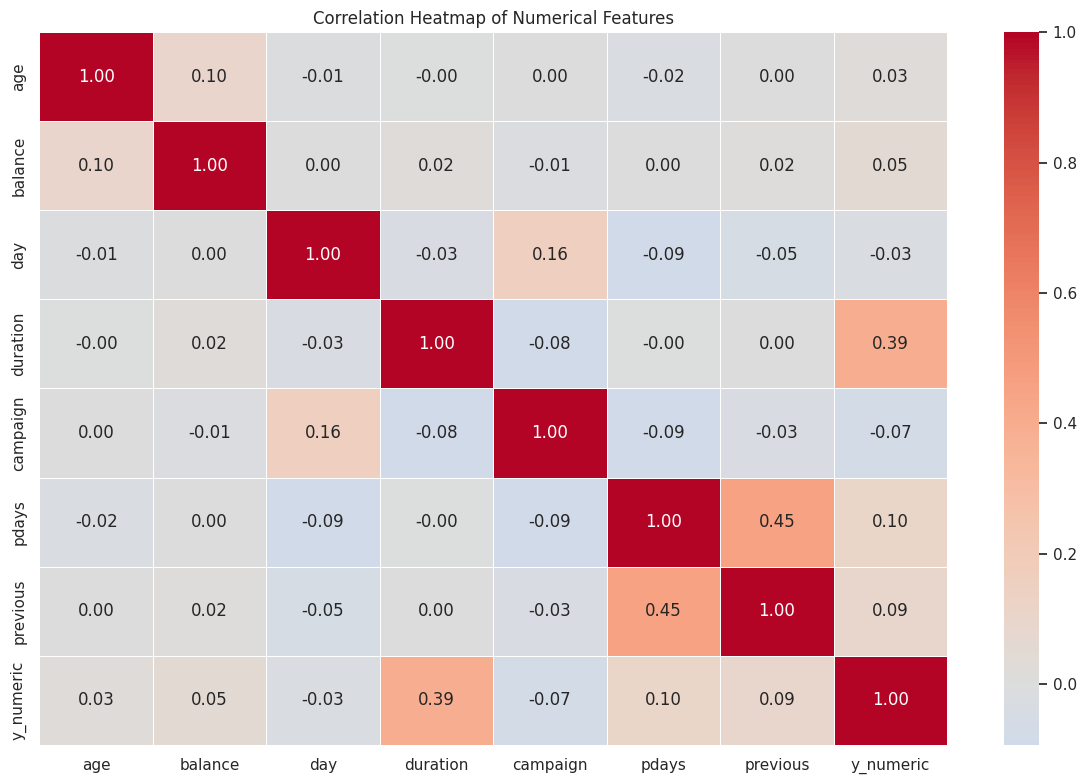

In [ ]:
# Plot correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Data Preparation & Feature Engineering

In [ ]:
# Define target variable
target_column = "y"

# Define features to exclude from modeling
excluded_features = ["y", "duration"]

# Create modeling feature matrix
X = df.drop(columns=excluded_features).copy()

# Encode target variable
y = df[target_column].map({
    "no": 0,
    "yes": 1
})

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (45211, 15)
Target shape: (45211,)

Target distribution:
y
0    39922
1     5289
Name: count, dtype: int64


In [ ]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

# Second split: divide the temporary data equally
# This creates 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

Training set: (31647, 15)
Validation set: (6782, 15)
Test set: (6782, 15)


In [ ]:
# Calculate target percentages for each dataset

split_distribution = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True) * 100,
    "Validation": y_val.value_counts(normalize=True) * 100,
    "Test": y_test.value_counts(normalize=True) * 100
})

split_distribution.index = ["No (0)", "Yes (1)"]

split_distribution

,Train,Validation,Test
No (0),88.302209,88.292539,88.307284
Yes (1),11.697791,11.707461,11.692716


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# Define numerical and categorical features
numerical_features = [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous"
]

categorical_features = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "poutcome"
]


# Numerical preprocessing
numerical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)


# Categorical preprocessing
categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)


# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

In [ ]:
# Fit the preprocessing pipeline using training data only
preprocessor.fit(X_train)

# Transform all three datasets
X_train_processed = preprocessor.transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_val_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (31647, 50)
Processed validation shape: (6782, 50)
Processed test shape: (6782, 50)


In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)


# Create a majority-class baseline
dummy_model = DummyClassifier(
    strategy="most_frequent"
)

# Train the baseline model
dummy_model.fit(
    X_train_processed,
    y_train
)

# Generate validation predictions
y_val_dummy = dummy_model.predict(X_val_processed)

# Evaluate baseline
dummy_accuracy = accuracy_score(y_val, y_val_dummy)
dummy_precision = precision_score(y_val, y_val_dummy, zero_division=0)
dummy_recall = recall_score(y_val, y_val_dummy, zero_division=0)
dummy_f1 = f1_score(y_val, y_val_dummy, zero_division=0)

print("Dummy Classifier Performance")
print("-" * 35)
print(f"Accuracy : {dummy_accuracy:.4f}")
print(f"Precision: {dummy_precision:.4f}")
print(f"Recall   : {dummy_recall:.4f}")
print(f"F1 Score : {dummy_f1:.4f}")

Dummy Classifier Performance
-----------------------------------
Accuracy : 0.8829
Precision: 0.0000
Recall   : 0.0000
F1 Score : 0.0000


# Logistic Regression Baseline

In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(
    X_train_processed,
    y_train
)

# Generate validation predictions
y_val_logistic = logistic_model.predict(X_val_processed)

# Generate probability predictions for the positive class
y_val_logistic_proba = logistic_model.predict_proba(
    X_val_processed
)[:, 1]

# Calculate evaluation metrics
logistic_accuracy = accuracy_score(
    y_val,
    y_val_logistic
)

logistic_precision = precision_score(
    y_val,
    y_val_logistic,
    zero_division=0
)

logistic_recall = recall_score(
    y_val,
    y_val_logistic,
    zero_division=0
)

logistic_f1 = f1_score(
    y_val,
    y_val_logistic,
    zero_division=0
)

logistic_roc_auc = roc_auc_score(
    y_val,
    y_val_logistic_proba
)

print("Logistic Regression Performance")
print("-" * 40)
print(f"Accuracy : {logistic_accuracy:.4f}")
print(f"Precision: {logistic_precision:.4f}")
print(f"Recall   : {logistic_recall:.4f}")
print(f"F1 Score : {logistic_f1:.4f}")
print(f"ROC-AUC  : {logistic_roc_auc:.4f}")

Logistic Regression Performance
----------------------------------------
Accuracy : 0.8931
Precision: 0.6575
Recall   : 0.1814
F1 Score : 0.2843
ROC-AUC  : 0.7699


# Threshold Analysis

In [ ]:
import numpy as np
import pandas as pd

threshold_results = []

thresholds = np.arange(0.10, 0.51, 0.05)

for threshold in thresholds:

    y_val_threshold = (
        y_val_logistic_proba >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val,
            y_val_threshold
        ),
        "Precision": precision_score(
            y_val,
            y_val_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_threshold,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            y_val_threshold,
            zero_division=0
        )
    })

threshold_results = pd.DataFrame(
    threshold_results
)

threshold_results

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.665143,0.216941,0.712846,0.332648
1,0.15,0.829696,0.350207,0.531486,0.422211
2,0.20,0.874816,0.463768,0.443325,0.453316
3,0.25,0.888971,0.535529,0.389169,0.450766
4,0.30,0.890888,0.556017,0.337531,0.420063
5,0.35,0.894279,0.594595,0.304786,0.402998
6,0.40,0.893394,0.604106,0.259446,0.362996
7,0.45,0.894132,0.635714,0.224181,0.331471
8,0.50,0.893099,0.657534,0.181360,0.284304


## Select Best Threshold

In [ ]:
best_threshold_row = threshold_results.loc[
    threshold_results["F1"].idxmax()
]

best_threshold = best_threshold_row["Threshold"]

print("Best Threshold:", best_threshold)
print(
    f"Best Validation F1: "
    f"{best_threshold_row['F1']:.4f}"
)

print(
    f"Validation Precision: "
    f"{best_threshold_row['Precision']:.4f}"
)

print(
    f"Validation Recall: "
    f"{best_threshold_row['Recall']:.4f}"
)

print(
    f"Validation Accuracy: "
    f"{best_threshold_row['Accuracy']:.4f}"
)

Best Threshold: 0.20000000000000004
Best Validation F1: 0.4533
Validation Precision: 0.4638
Validation Recall: 0.4433
Validation Accuracy: 0.8748


# Balanced Logistic Regression

In [ ]:
# Initialize class-weighted Logistic Regression

logistic_balanced = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_balanced.fit(
    X_train_processed,
    y_train
)

# Validation predictions
y_val_balanced = logistic_balanced.predict(
    X_val_processed
)

# Validation probabilities
y_val_balanced_proba = logistic_balanced.predict_proba(
    X_val_processed
)[:, 1]

# Calculate metrics
balanced_accuracy = accuracy_score(
    y_val,
    y_val_balanced
)

balanced_precision = precision_score(
    y_val,
    y_val_balanced,
    zero_division=0
)

balanced_recall = recall_score(
    y_val,
    y_val_balanced,
    zero_division=0
)

balanced_f1 = f1_score(
    y_val,
    y_val_balanced,
    zero_division=0
)

balanced_roc_auc = roc_auc_score(
    y_val,
    y_val_balanced_proba
)

print("Class-Weighted Logistic Regression")
print("-" * 45)
print(f"Accuracy : {balanced_accuracy:.4f}")
print(f"Precision: {balanced_precision:.4f}")
print(f"Recall   : {balanced_recall:.4f}")
print(f"F1 Score : {balanced_f1:.4f}")
print(f"ROC-AUC  : {balanced_roc_auc:.4f}")

Class-Weighted Logistic Regression
---------------------------------------------
Accuracy : 0.7566
Precision: 0.2688
Recall   : 0.6272
F1 Score : 0.3763
ROC-AUC  : 0.7720


# Random Forest Baseline

In [ ]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest
random_forest = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest.fit(
    X_train_processed,
    y_train
)

# Validation predictions
y_val_rf = random_forest.predict(X_val_processed)

# Validation probabilities
y_val_rf_proba = random_forest.predict_proba(
    X_val_processed
)[:, 1]

# Calculate metrics
rf_accuracy = accuracy_score(
    y_val,
    y_val_rf
)

rf_precision = precision_score(
    y_val,
    y_val_rf,
    zero_division=0
)

rf_recall = recall_score(
    y_val,
    y_val_rf,
    zero_division=0
)

rf_f1 = f1_score(
    y_val,
    y_val_rf,
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_val,
    y_val_rf_proba
)

print("Random Forest Performance")
print("-" * 35)
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1 Score : {rf_f1:.4f}")
print(f"ROC-AUC  : {rf_roc_auc:.4f}")

Random Forest Performance
-----------------------------------
Accuracy : 0.8944
Precision: 0.6477
Recall   : 0.2154
F1 Score : 0.3233
ROC-AUC  : 0.7966


# Cross Validation + Hyperparameter Tuning

In [ ]:
from sklearn.pipeline import Pipeline

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("Cross-validation strategy:")
print(cv_strategy)

Cross-validation strategy:
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


# Random Forest Cross-Validation

In [ ]:
from sklearn.model_selection import cross_val_score

rf_cv_scores = cross_val_score(
    rf_pipeline,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring="f1",
    n_jobs=-1
)

print("Random Forest 5-Fold Cross-Validation")
print("-" * 45)

for i, score in enumerate(rf_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("-" * 45)
print(f"Mean F1: {rf_cv_scores.mean():.4f}")
print(f"Std F1 : {rf_cv_scores.std():.4f}")

Random Forest 5-Fold Cross-Validation
---------------------------------------------
Fold 1: 0.2992
Fold 2: 0.3180
Fold 3: 0.3360
Fold 4: 0.3085
Fold 5: 0.2383
---------------------------------------------
Mean F1: 0.3000
Std F1 : 0.0332


# Random Forest Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint


# Define the hyperparameter search space
rf_param_distributions = {
    "model__n_estimators": randint(200, 600),
    "model__max_depth": [None, 8, 12, 16, 20, 25],
    "model__min_samples_split": randint(2, 15),
    "model__min_samples_leaf": randint(1, 8),
    "model__max_features": ["sqrt", "log2", 0.5, 0.7],
    "model__class_weight": [
        "balanced",
        "balanced_subsample"
    ]
}


# Create RandomizedSearchCV
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_distributions,
    n_iter=30,
    scoring="f1",
    cv=cv_strategy,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)


# Run hyperparameter search
rf_random_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


RandomizedSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImputer(strategy='median')),
                                                                                               ('scaler',
                                                                                                StandardScaler())]),
                                                                               ['age',
                                                                                'balance',
                                                                                'day',
                                                                                'campaign',
                                                                                'pdays',
                                                                                'previous']),
                                                                              ('cat',
                                                                               Pipeline(steps=[('imputer',
                                                                                                SimpleImpu...
                                        'model__min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792bf6a0fd10>,
                                        'model__min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792bf6c97f80>,
                                        'model__n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x792bf6d6b170>},
                   random_state=42, return_train_score=True, scoring='f1',
                   verbose=1)

# Best Random Forest Parameters

In [ ]:
print("Best Random Forest Parameters:")
print("-" * 40)

for parameter, value in rf_random_search.best_params_.items():
    print(f"{parameter}: {value}")

print("\nBest Cross-Validation F1:")
print(f"{rf_random_search.best_score_:.4f}")

Best Random Forest Parameters:
----------------------------------------
model__class_weight: balanced_subsample
model__max_depth: None
model__max_features: 0.7
model__min_samples_leaf: 7
model__min_samples_split: 10
model__n_estimators: 527

Best Cross-Validation F1:
0.4693


# Tuned Random Forest Validation Performance

In [ ]:
# Best tuned Random Forest
best_rf = rf_random_search.best_estimator_

# Validation predictions
y_val_rf_tuned = best_rf.predict(X_val)

# Validation probabilities
y_val_rf_tuned_proba = best_rf.predict_proba(X_val)[:, 1]

# Calculate metrics
rf_tuned_accuracy = accuracy_score(
    y_val,
    y_val_rf_tuned
)

rf_tuned_precision = precision_score(
    y_val,
    y_val_rf_tuned,
    zero_division=0
)

rf_tuned_recall = recall_score(
    y_val,
    y_val_rf_tuned,
    zero_division=0
)

rf_tuned_f1 = f1_score(
    y_val,
    y_val_rf_tuned,
    zero_division=0
)

rf_tuned_roc_auc = roc_auc_score(
    y_val,
    y_val_rf_tuned_proba
)

print("Tuned Random Forest Performance")
print("-" * 45)
print(f"Accuracy : {rf_tuned_accuracy:.4f}")
print(f"Precision: {rf_tuned_precision:.4f}")
print(f"Recall   : {rf_tuned_recall:.4f}")
print(f"F1 Score : {rf_tuned_f1:.4f}")
print(f"ROC-AUC  : {rf_tuned_roc_auc:.4f}")

Tuned Random Forest Performance
---------------------------------------------
Accuracy : 0.8769
Precision: 0.4759
Recall   : 0.5088
F1 Score : 0.4918
ROC-AUC  : 0.7965


# Threshold Optimization for Tuned Random Forest

In [ ]:
# Get the best tuned Random Forest
best_rf = rf_random_search.best_estimator_

# Generate probability predictions on the validation set
y_val_rf_proba = best_rf.predict_proba(X_val)[:, 1]

# Store threshold evaluation results
rf_threshold_results = []

thresholds = np.arange(0.10, 0.51, 0.01)

for threshold in thresholds:

    y_val_threshold = (
        y_val_rf_proba >= threshold
    ).astype(int)

    rf_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val,
            y_val_threshold
        ),
        "Precision": precision_score(
            y_val,
            y_val_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_threshold,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            y_val_threshold,
            zero_division=0
        )
    })

rf_threshold_results = pd.DataFrame(
    rf_threshold_results
)

rf_threshold_results.head()

,Threshold,Accuracy,Precision,Recall,F1
0,0.10,0.354910,0.145936,0.929471,0.252265
1,0.11,0.387054,0.150488,0.911839,0.258341
2,0.12,0.421115,0.156880,0.901763,0.267264
3,0.13,0.456060,0.163919,0.889169,0.276808
4,0.14,0.490268,0.171316,0.874055,0.286481


In [ ]:
best_rf_threshold_row = rf_threshold_results.loc[
    rf_threshold_results["F1"].idxmax()
]

best_rf_threshold = best_rf_threshold_row["Threshold"]

print("Best Random Forest Threshold")
print("-" * 40)
print(f"Threshold : {best_rf_threshold:.2f}")
print(f"Accuracy  : {best_rf_threshold_row['Accuracy']:.4f}")
print(f"Precision : {best_rf_threshold_row['Precision']:.4f}")
print(f"Recall    : {best_rf_threshold_row['Recall']:.4f}")
print(f"F1 Score  : {best_rf_threshold_row['F1']:.4f}")

Best Random Forest Threshold
----------------------------------------
Threshold : 0.44
Accuracy  : 0.8652
Precision : 0.4409
Recall    : 0.5642
F1 Score  : 0.4950


# Model Comperation

In [ ]:
model_comparison = pd.DataFrame([
    {
        "Model": "Dummy Classifier",
        "Accuracy": dummy_accuracy,
        "Precision": dummy_precision,
        "Recall": dummy_recall,
        "F1": dummy_f1,
        "ROC-AUC": np.nan
    },
    {
        "Model": "Logistic Regression",
        "Accuracy": logistic_accuracy,
        "Precision": logistic_precision,
        "Recall": logistic_recall,
        "F1": logistic_f1,
        "ROC-AUC": logistic_roc_auc
    },
    {
        "Model": "Logistic + Threshold",
        "Accuracy": best_threshold_row["Accuracy"],
        "Precision": best_threshold_row["Precision"],
        "Recall": best_threshold_row["Recall"],
        "F1": best_threshold_row["F1"],
        "ROC-AUC": logistic_roc_auc
    },
    {
        "Model": "Balanced Logistic Regression",
        "Accuracy": balanced_accuracy,
        "Precision": balanced_precision,
        "Recall": balanced_recall,
        "F1": balanced_f1,
        "ROC-AUC": balanced_roc_auc
    },
    {
        "Model": "Random Forest",
        "Accuracy": rf_accuracy,
        "Precision": rf_precision,
        "Recall": rf_recall,
        "F1": rf_f1,
        "ROC-AUC": rf_roc_auc
    },
    {
        "Model": "Tuned Random Forest",
        "Accuracy": rf_tuned_accuracy,
        "Precision": rf_tuned_precision,
        "Recall": rf_tuned_recall,
        "F1": rf_tuned_f1,
        "ROC-AUC": rf_tuned_roc_auc
    },
    {
        "Model": "Tuned Random Forest + Threshold",
        "Accuracy": best_rf_threshold_row["Accuracy"],
        "Precision": best_rf_threshold_row["Precision"],
        "Recall": best_rf_threshold_row["Recall"],
        "F1": best_rf_threshold_row["F1"],
        "ROC-AUC": rf_tuned_roc_auc
    }
])

model_comparison = (
    model_comparison
    .sort_values("F1", ascending=False)
    .reset_index(drop=True)
)

model_comparison

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Tuned Random Forest + Threshold,0.865231,0.440945,0.564232,0.495028,0.796511
1,Tuned Random Forest,0.876880,0.475854,0.508816,0.491783,0.796511
2,Logistic + Threshold,0.874816,0.463768,0.443325,0.453316,0.769888
3,Balanced Logistic Regression,0.756561,0.268753,0.627204,0.376275,0.771966
4,Random Forest,0.894426,0.647727,0.215365,0.323251,0.796620
5,Logistic Regression,0.893099,0.657534,0.181360,0.284304,0.769888
6,Dummy Classifier,0.882925,0.000000,0.000000,0.000000,NaN


# HistGradientBoosting

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import Pipeline

hist_gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            HistGradientBoostingClassifier(
                max_iter=300,
                learning_rate=0.05,
                max_leaf_nodes=31,
                min_samples_leaf=20,
                l2_regularization=1.0,
                random_state=42
            )
        )
    ]
)

hist_gb_pipeline.fit(
    X_train,
    y_train
)

y_val_hgb = hist_gb_pipeline.predict(X_val)

y_val_hgb_proba = (
    hist_gb_pipeline.predict_proba(X_val)[:, 1]
)

hgb_accuracy = accuracy_score(
    y_val,
    y_val_hgb
)

hgb_precision = precision_score(
    y_val,
    y_val_hgb,
    zero_division=0
)

hgb_recall = recall_score(
    y_val,
    y_val_hgb,
    zero_division=0
)

hgb_f1 = f1_score(
    y_val,
    y_val_hgb,
    zero_division=0
)

hgb_roc_auc = roc_auc_score(
    y_val,
    y_val_hgb_proba
)

print("HistGradientBoosting Performance")
print("-" * 45)
print(f"Accuracy : {hgb_accuracy:.4f}")
print(f"Precision: {hgb_precision:.4f}")
print(f"Recall   : {hgb_recall:.4f}")
print(f"F1 Score : {hgb_f1:.4f}")
print(f"ROC-AUC  : {hgb_roc_auc:.4f}")

HistGradientBoosting Performance
---------------------------------------------
Accuracy : 0.8949
Precision: 0.6441
Recall   : 0.2280
F1 Score : 0.3367
ROC-AUC  : 0.8054


# HistGradientBoosting Threshold Optimization

In [ ]:
hgb_threshold_results = []

thresholds = np.arange(0.10, 0.51, 0.01)

for threshold in thresholds:

    y_val_hgb_threshold = (
        y_val_hgb_proba >= threshold
    ).astype(int)

    hgb_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val,
            y_val_hgb_threshold
        ),
        "Precision": precision_score(
            y_val,
            y_val_hgb_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_hgb_threshold,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            y_val_hgb_threshold,
            zero_division=0
        )
    })

hgb_threshold_results = pd.DataFrame(
    hgb_threshold_results
)

hgb_threshold_results.sort_values(
    "F1",
    ascending=False
).head(10)

,Threshold,Accuracy,Precision,Recall,F1
11,0.21,0.875700,0.472626,0.532746,0.500888
9,0.19,0.870835,0.457203,0.551637,0.500000
10,0.20,0.873194,0.464130,0.537783,0.498250
12,0.22,0.876880,0.476410,0.521411,0.497895
8,0.18,0.866116,0.443452,0.562972,0.496115
13,0.23,0.877765,0.479191,0.507557,0.492966
7,0.17,0.861545,0.431149,0.571788,0.491608
14,0.24,0.878797,0.482885,0.497481,0.490074
15,0.25,0.880714,0.490470,0.486146,0.488299
6,0.16,0.856532,0.419151,0.584383,0.488164


In [ ]:
best_hgb_threshold_row = hgb_threshold_results.loc[
    hgb_threshold_results["F1"].idxmax()
]

best_hgb_threshold = best_hgb_threshold_row["Threshold"]

print("Best HistGradientBoosting Threshold")
print("-" * 45)
print(f"Threshold : {best_hgb_threshold:.2f}")
print(f"Accuracy  : {best_hgb_threshold_row['Accuracy']:.4f}")
print(f"Precision : {best_hgb_threshold_row['Precision']:.4f}")
print(f"Recall    : {best_hgb_threshold_row['Recall']:.4f}")
print(f"F1 Score  : {best_hgb_threshold_row['F1']:.4f}")

Best HistGradientBoosting Threshold
---------------------------------------------
Threshold : 0.21
Accuracy  : 0.8757
Precision : 0.4726
Recall    : 0.5327
F1 Score  : 0.5009


# HistGradientBoosting Cross-Validation

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

hgb_cv_scores = cross_val_score(
    hist_gb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("HistGradientBoosting 5-Fold Cross-Validation")
print("-" * 50)

for i, score in enumerate(hgb_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("-" * 50)
print(f"Mean F1: {hgb_cv_scores.mean():.4f}")
print(f"Std F1 : {hgb_cv_scores.std():.4f}")

HistGradientBoosting 5-Fold Cross-Validation
--------------------------------------------------
Fold 1: 0.3350
Fold 2: 0.3636
Fold 3: 0.3244
Fold 4: 0.3615
Fold 5: 0.2782
--------------------------------------------------
Mean F1: 0.3325
Std F1 : 0.0311


# XGBoost

In [ ]:
!pip install -q xgboost

In [ ]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

In [ ]:
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                learning_rate=0.05,
                max_depth=4,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

xgb_pipeline.fit(
    X_train,
    y_train
)

y_val_xgb = xgb_pipeline.predict(X_val)

y_val_xgb_proba = (
    xgb_pipeline.predict_proba(X_val)[:, 1]
)

xgb_accuracy = accuracy_score(
    y_val,
    y_val_xgb
)

xgb_precision = precision_score(
    y_val,
    y_val_xgb,
    zero_division=0
)

xgb_recall = recall_score(
    y_val,
    y_val_xgb,
    zero_division=0
)

xgb_f1 = f1_score(
    y_val,
    y_val_xgb,
    zero_division=0
)

xgb_roc_auc = roc_auc_score(
    y_val,
    y_val_xgb_proba
)

print("XGBoost Baseline Performance")
print("-" * 45)
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")

XGBoost Baseline Performance
---------------------------------------------
Accuracy : 0.8953
Precision: 0.6556
Recall   : 0.2229
F1 Score : 0.3327
ROC-AUC  : 0.8077


# XGBoost Threshold Optimization

In [ ]:
xgb_threshold_results = []

thresholds = np.arange(0.10, 0.51, 0.01)

for threshold in thresholds:

    y_val_xgb_threshold = (
        y_val_xgb_proba >= threshold
    ).astype(int)

    xgb_threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_val,
            y_val_xgb_threshold
        ),
        "Precision": precision_score(
            y_val,
            y_val_xgb_threshold,
            zero_division=0
        ),
        "Recall": recall_score(
            y_val,
            y_val_xgb_threshold,
            zero_division=0
        ),
        "F1": f1_score(
            y_val,
            y_val_xgb_threshold,
            zero_division=0
        )
    })

xgb_threshold_results = pd.DataFrame(
    xgb_threshold_results
)

xgb_threshold_results.sort_values(
    "F1",
    ascending=False
).head(10)

,Threshold,Accuracy,Precision,Recall,F1
11,0.21,0.879387,0.485646,0.511335,0.498160
10,0.20,0.876585,0.475372,0.522670,0.497900
9,0.19,0.873046,0.463547,0.536524,0.497373
7,0.17,0.864789,0.440233,0.570529,0.496983
8,0.18,0.868770,0.450311,0.547859,0.494318
6,0.16,0.858891,0.425435,0.585642,0.492846
13,0.23,0.882925,0.500000,0.484887,0.492327
14,0.24,0.884400,0.506702,0.476071,0.490909
12,0.22,0.879092,0.483990,0.494962,0.489415
16,0.26,0.886759,0.518310,0.463476,0.489362


In [ ]:
best_xgb_threshold_row = xgb_threshold_results.loc[
    xgb_threshold_results["F1"].idxmax()
]

best_xgb_threshold = best_xgb_threshold_row["Threshold"]

print("Best XGBoost Threshold")
print("-" * 40)
print(f"Threshold : {best_xgb_threshold:.2f}")
print(f"Accuracy  : {best_xgb_threshold_row['Accuracy']:.4f}")
print(f"Precision : {best_xgb_threshold_row['Precision']:.4f}")
print(f"Recall    : {best_xgb_threshold_row['Recall']:.4f}")
print(f"F1 Score  : {best_xgb_threshold_row['F1']:.4f}")

Best XGBoost Threshold
----------------------------------------
Threshold : 0.21
Accuracy  : 0.8794
Precision : 0.4856
Recall    : 0.5113
F1 Score  : 0.4982


# XGBoost Cross-Validation

In [ ]:
xgb_cv_scores = cross_val_score(
    xgb_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

print("XGBoost 5-Fold Cross-Validation")
print("-" * 45)

for i, score in enumerate(xgb_cv_scores, start=1):
    print(f"Fold {i}: {score:.4f}")

print("-" * 45)
print(f"Mean F1: {xgb_cv_scores.mean():.4f}")
print(f"Std F1 : {xgb_cv_scores.std():.4f}")

XGBoost 5-Fold Cross-Validation
---------------------------------------------
Fold 1: 0.3393
Fold 2: 0.3474
Fold 3: 0.3512
Fold 4: 0.3473
Fold 5: 0.2735
---------------------------------------------
Mean F1: 0.3317
Std F1 : 0.0294


# Final Model Selection

In [ ]:
final_model_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Validation F1": logistic_f1,
        "ROC-AUC": logistic_roc_auc,
        "CV Mean F1": np.nan,
        "CV Std F1": np.nan
    },
    {
        "Model": "Random Forest",
        "Validation F1": rf_f1,
        "ROC-AUC": rf_roc_auc,
        "CV Mean F1": rf_cv_scores.mean(),
        "CV Std F1": rf_cv_scores.std()
    },
    {
        "Model": "Tuned Random Forest",
        "Validation F1": rf_tuned_f1,
        "ROC-AUC": rf_tuned_roc_auc,
        "CV Mean F1": rf_random_search.best_score_,
        "CV Std F1": np.nan
    },
    {
        "Model": "HistGradientBoosting",
        "Validation F1": hgb_f1,
        "ROC-AUC": hgb_roc_auc,
        "CV Mean F1": hgb_cv_scores.mean(),
        "CV Std F1": hgb_cv_scores.std()
    },
    {
        "Model": "XGBoost",
        "Validation F1": xgb_f1,
        "ROC-AUC": xgb_roc_auc,
        "CV Mean F1": xgb_cv_scores.mean(),
        "CV Std F1": xgb_cv_scores.std()
    }
])

final_model_comparison.sort_values(
    "CV Mean F1",
    ascending=False,
    na_position="last"
).reset_index(drop=True)

,Model,Validation F1,ROC-AUC,CV Mean F1,CV Std F1
0,Tuned Random Forest,0.491783,0.796511,0.469291,NaN
1,HistGradientBoosting,0.336744,0.805400,0.332546,0.031078
2,XGBoost,0.332707,0.807720,0.331729,0.029390
3,Random Forest,0.323251,0.796620,0.300003,0.033170
4,Logistic Regression,0.284304,0.769888,NaN,NaN


# Final Validation Evaluation

In [ ]:
# Final model selected based on cross-validation and validation performance
final_model = rf_random_search.best_estimator_

# Final classification threshold selected using validation data
final_threshold = best_rf_threshold

print("Final Model Configuration")
print("-" * 45)
print("Model     : Tuned Random Forest")
print(f"Threshold : {final_threshold:.2f}")

Final Model Configuration
---------------------------------------------
Model     : Tuned Random Forest
Threshold : 0.44


# Final Validation Performance

In [ ]:
# Generate validation probabilities
y_val_final_proba = final_model.predict_proba(X_val)[:, 1]

# Apply the final threshold
y_val_final = (
    y_val_final_proba >= final_threshold
).astype(int)

# Calculate final validation metrics
final_val_accuracy = accuracy_score(
    y_val,
    y_val_final
)

final_val_precision = precision_score(
    y_val,
    y_val_final,
    zero_division=0
)

final_val_recall = recall_score(
    y_val,
    y_val_final,
    zero_division=0
)

final_val_f1 = f1_score(
    y_val,
    y_val_final,
    zero_division=0
)

final_val_roc_auc = roc_auc_score(
    y_val,
    y_val_final_proba
)

print("Final Validation Performance")
print("-" * 45)
print(f"Accuracy : {final_val_accuracy:.4f}")
print(f"Precision: {final_val_precision:.4f}")
print(f"Recall   : {final_val_recall:.4f}")
print(f"F1 Score : {final_val_f1:.4f}")
print(f"ROC-AUC  : {final_val_roc_auc:.4f}")

Final Validation Performance
---------------------------------------------
Accuracy : 0.8652
Precision: 0.4409
Recall   : 0.5642
F1 Score : 0.4950
ROC-AUC  : 0.7965


# Final Test Evaluation

In [ ]:
# Generate probability predictions on the untouched test set
y_test_final_proba = final_model.predict_proba(X_test)[:, 1]

# Apply the final threshold selected from the validation set
y_test_final = (
    y_test_final_proba >= final_threshold
).astype(int)

# Calculate final test metrics
test_accuracy = accuracy_score(
    y_test,
    y_test_final
)

test_precision = precision_score(
    y_test,
    y_test_final,
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_test_final,
    zero_division=0
)

test_f1 = f1_score(
    y_test,
    y_test_final,
    zero_division=0
)

test_roc_auc = roc_auc_score(
    y_test,
    y_test_final_proba
)

print("Final Test Performance")
print("-" * 45)
print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1 Score : {test_f1:.4f}")
print(f"ROC-AUC  : {test_roc_auc:.4f}")

Final Test Performance
---------------------------------------------
Accuracy : 0.8618
Precision: 0.4283
Recall   : 0.5422
F1 Score : 0.4786
ROC-AUC  : 0.7832


# Confusion Matrix

Confusion Matrix
------------------------------
[[5415  574]
 [ 363  430]]


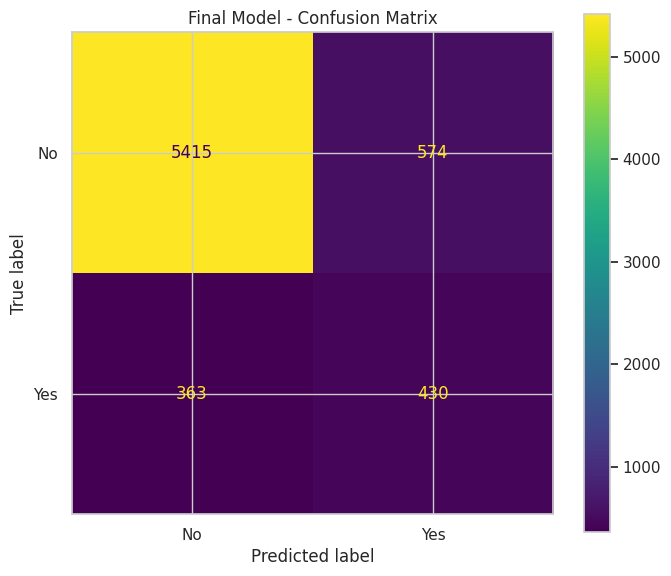

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(
    y_test,
    y_test_final
)

print("Confusion Matrix")
print("-" * 30)
print(cm)

# Visualize confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

ax.set_title("Final Model - Confusion Matrix")
plt.tight_layout()
plt.show()

# Final Classification Report

In [ ]:
from sklearn.metrics import classification_report

print("Final Classification Report")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_test_final,
        target_names=["No Subscription", "Subscription"],
        digits=4
    )
)

Final Classification Report
                 precision    recall  f1-score   support

No Subscription     0.9372    0.9042    0.9204      5989
   Subscription     0.4283    0.5422    0.4786       793

       accuracy                         0.8618      6782
      macro avg     0.6827    0.7232    0.6995      6782
   weighted avg     0.8777    0.8618    0.8687      6782



# ROC Curve and ROC-AUC

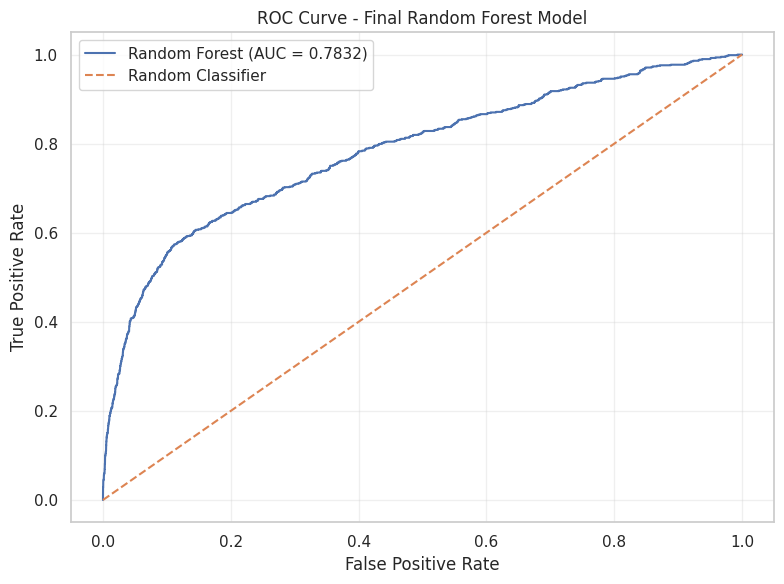

Test ROC-AUC: 0.7832


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    y_test_final_proba
)

# Calculate ROC-AUC
roc_auc = roc_auc_score(
    y_test,
    y_test_final_proba
)

# Plot ROC Curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Random Forest Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Test ROC-AUC: {roc_auc:.4f}")

# Precision-Recall Curve

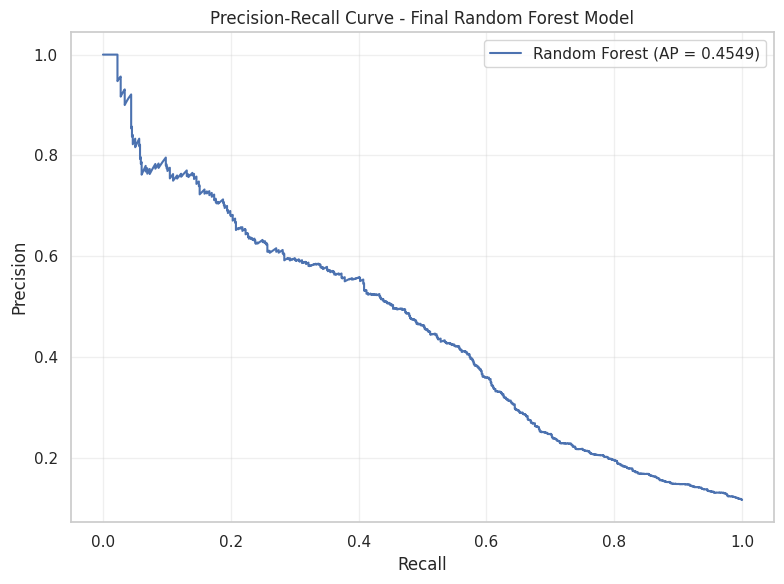

Average Precision (PR-AUC): 0.4549


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculate Precision-Recall curve
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_test_final_proba
)

# Calculate Average Precision
average_precision = average_precision_score(
    y_test,
    y_test_final_proba
)

# Plot Precision-Recall Curve
plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"Random Forest (AP = {average_precision:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Final Random Forest Model")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Average Precision (PR-AUC): {average_precision:.4f}")

"The dataset is highly imbalanced, with only 11.7% positive cases. Therefore, Accuracy can be misleading. I focused on Precision, Recall, F1 Score, ROC-AUC and Precision-Recall analysis to properly evaluate the minority class."

# Feature Importance

In [ ]:
print(final_model.named_steps.keys())

dict_keys(['preprocessor', 'model'])


In [ ]:
# Extract preprocessing and model components
preprocessor = final_model.named_steps["preprocessor"]
rf_model = final_model.named_steps["model"]

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importances = rf_model.feature_importances_

# Create feature importance dataframe
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

# Display top 20 features
feature_importance_df.head(20)

,Feature,Importance
0,num__balance,0.182536
1,num__age,0.123012
2,num__day,0.121762
3,cat__poutcome_success,0.102895
4,cat__contact_unknown,0.064196
5,num__campaign,0.054299
6,num__pdays,0.038759
7,cat__month_aug,0.018850
8,cat__housing_yes,0.018373
9,cat__month_jul,0.017279


# Top Feature Importance Visualization

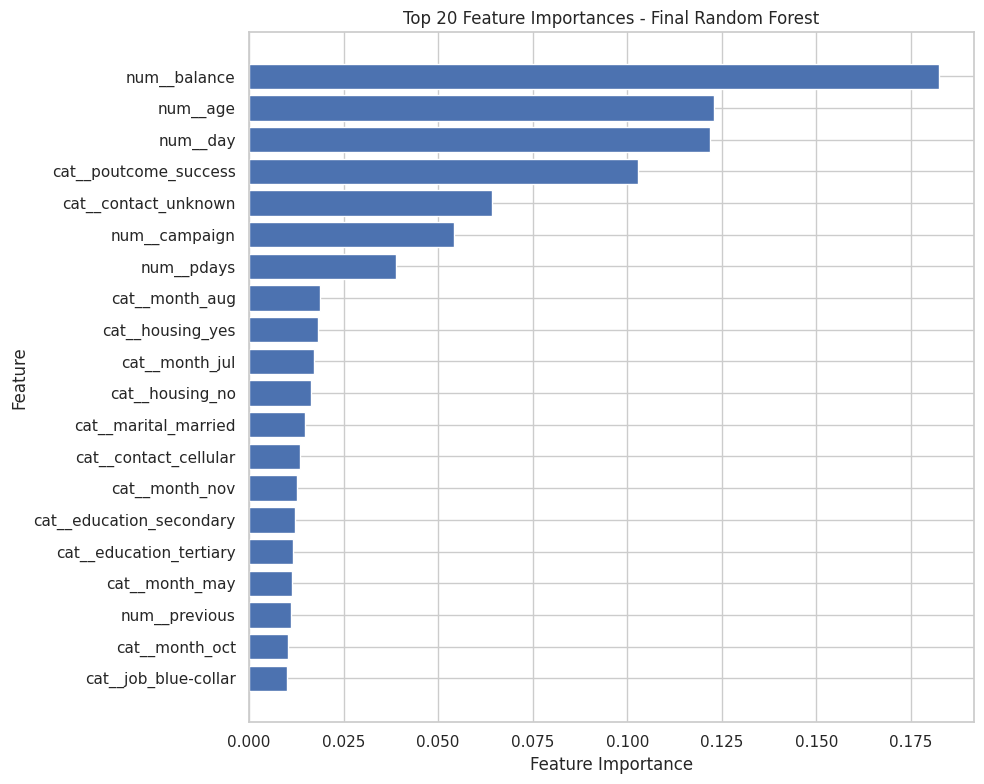

In [ ]:
top_features = feature_importance_df.head(20).sort_values(
    "Importance",
    ascending=True
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Feature Importances - Final Random Forest")

plt.tight_layout()
plt.show()

## 19. SHAP Explainability

SHAP (SHapley Additive exPlanations) is used to provide detailed explanations
of the final Random Forest predictions.

While traditional feature importance measures how frequently or strongly a
feature contributes to the model overall, SHAP explains both:

- The magnitude of a feature's contribution.
- The direction of its contribution toward the positive or negative class.

This allows us to understand not only which features are important, but also
how their values influence the model's predictions.

In [ ]:
!pip install -q shap

In [ ]:
import shap
import numpy as np
import pandas as pd

# Extract preprocessing and Random Forest model
preprocessor = final_model.named_steps["preprocessor"]
rf_model = final_model.named_steps["model"]

# Transform the test data using the already-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Convert sparse matrix to dense if necessary
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

print("Processed Test Shape:", X_test_processed.shape)
print("Number of Feature Names:", len(feature_names))

Processed Test Shape: (6782, 50)
Number of Feature Names: 50


In [ ]:
# Select a representative sample for SHAP analysis
shap_sample_size = min(1000, X_test_processed.shape[0])

rng = np.random.RandomState(42)

sample_indices = rng.choice(
    X_test_processed.shape[0],
    size=shap_sample_size,
    replace=False
)

X_shap = X_test_processed[sample_indices]

print("SHAP Sample Shape:", X_shap.shape)

SHAP Sample Shape: (1000, 50)


In [ ]:
print("final_model:", "final_model" in globals())
print("rf_model:", "rf_model" in globals())
print("X_test:", "X_test" in globals())
print("X_test_processed:", "X_test_processed" in globals())
print("X_shap:", "X_shap" in globals())
print("shap_values:", "shap_values" in globals())

final_model: True
rf_model: True
X_test: True
X_test_processed: True
X_shap: True
shap_values: False


In [ ]:
# Create SHAP TreeExplainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")

SHAP values calculated successfully.


In [ ]:
# Extract SHAP values for the positive class
if isinstance(shap_values, list):
    shap_values_positive = shap_values[1]

elif isinstance(shap_values, np.ndarray) and shap_values.ndim == 3:
    shap_values_positive = shap_values[:, :, 1]

else:
    shap_values_positive = shap_values

print("SHAP Matrix Shape:", shap_values_positive.shape)

SHAP Matrix Shape: (1000, 50)


/tmp/ipykernel_1020/469709183.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


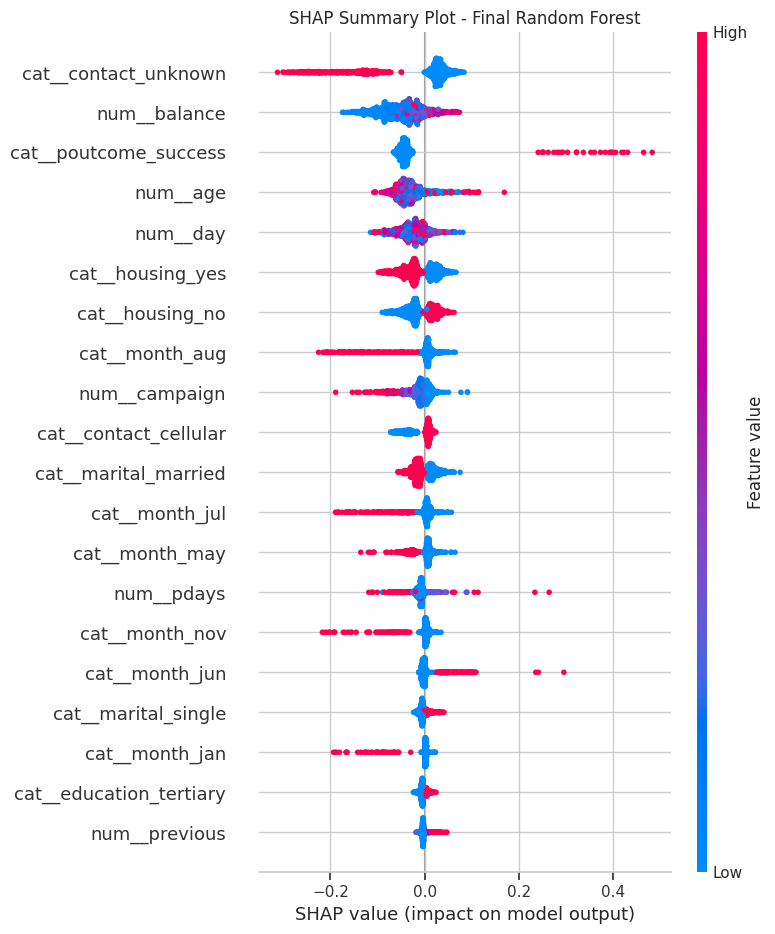

In [ ]:
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values_positive,
    X_shap,
    feature_names=feature_names,
    max_display=20,
    show=False
)

plt.title("SHAP Summary Plot - Final Random Forest")
plt.tight_layout()
plt.show()

In [ ]:
# Calculate mean absolute SHAP values
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(shap_values_positive).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
).reset_index(drop=True)

shap_importance.head(20)

,Feature,Mean_Absolute_SHAP
0,cat__contact_unknown,0.071232
1,num__balance,0.052035
2,cat__poutcome_success,0.051907
3,num__age,0.038642
4,num__day,0.029490
5,cat__housing_yes,0.029305
6,cat__housing_no,0.026309
7,cat__month_aug,0.024862
8,num__campaign,0.020855
9,cat__contact_cellular,0.020291


In [ ]:
# Analyze SHAP direction for the top 20 features

top_20_features = shap_importance.head(20)["Feature"].tolist()

direction_results = []

for feature in top_20_features:
    feature_idx = list(feature_names).index(feature)

    mean_shap = shap_values_positive[:, feature_idx].mean()
    mean_abs_shap = np.abs(
        shap_values_positive[:, feature_idx]
    ).mean()

    direction_results.append({
        "Feature": feature,
        "Mean_SHAP": mean_shap,
        "Mean_Absolute_SHAP": mean_abs_shap
    })

shap_direction_df = pd.DataFrame(direction_results)

shap_direction_df

,Feature,Mean_SHAP,Mean_Absolute_SHAP
0,cat__contact_unknown,-0.026354,0.071232
1,num__balance,-0.047390,0.052035
2,cat__poutcome_success,-0.033386,0.051907
3,num__age,-0.030608,0.038642
4,num__day,-0.024995,0.029490
5,cat__housing_yes,-0.011268,0.029305
6,cat__housing_no,-0.010423,0.026309
7,cat__month_aug,-0.008400,0.024862
8,num__campaign,-0.014282,0.020855
9,cat__contact_cellular,-0.009007,0.020291


In [ ]:
# Create a detailed SHAP direction table for the top features

top_features = shap_importance.head(10)["Feature"].tolist()

detailed_shap_analysis = []

for feature in top_features:
    idx = list(feature_names).index(feature)

    feature_values = X_shap[:, idx]
    feature_shap = shap_values_positive[:, idx]

    detailed_shap_analysis.append({
        "Feature": feature,
        "Mean_SHAP": feature_shap.mean(),
        "Mean_Abs_SHAP": np.abs(feature_shap).mean(),
        "Min_SHAP": feature_shap.min(),
        "Max_SHAP": feature_shap.max(),
        "Positive_SHAP_%": (feature_shap > 0).mean() * 100,
        "Negative_SHAP_%": (feature_shap < 0).mean() * 100
    })

detailed_shap_analysis = pd.DataFrame(detailed_shap_analysis)

detailed_shap_analysis

,Feature,Mean_SHAP,Mean_Abs_SHAP,Min_SHAP,Max_SHAP,Positive_SHAP_%,Negative_SHAP_%
0,cat__contact_unknown,-0.026354,0.071232,-0.312385,0.083928,70.4,29.6
1,num__balance,-0.047390,0.052035,-0.174373,0.074011,10.8,89.2
2,cat__poutcome_success,-0.033386,0.051907,-0.066300,0.483523,2.7,97.3
3,num__age,-0.030608,0.038642,-0.107838,0.169327,11.7,88.3
4,num__day,-0.024995,0.029490,-0.114814,0.081353,15.3,84.7
5,cat__housing_yes,-0.011268,0.029305,-0.098401,0.066807,40.2,59.8
6,cat__housing_no,-0.010423,0.026309,-0.089972,0.062666,39.8,60.2
7,cat__month_aug,-0.008400,0.024862,-0.225137,0.065317,82.1,17.9
8,num__campaign,-0.014282,0.020855,-0.188799,0.091189,33.9,66.1
9,cat__contact_cellular,-0.009007,0.020291,-0.071903,0.024029,63.5,36.5


SHAP analysis identified contact method, account balance, previous campaign outcome, age, and campaign timing as the most influential factors in the final Random Forest predictions. In particular, unknown contact information showed the strongest overall contribution and was associated with lower predicted subscription probability, while previous campaign success emerged as a strong predictive signal.

When the feature value increases, does the model become more or less likely to predict Subscription?

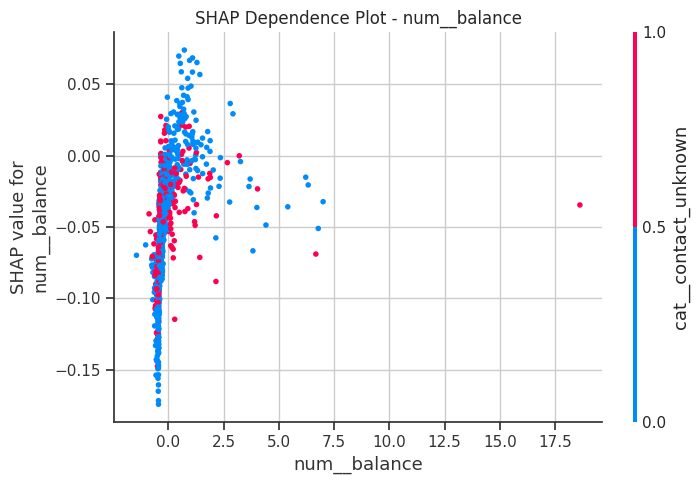

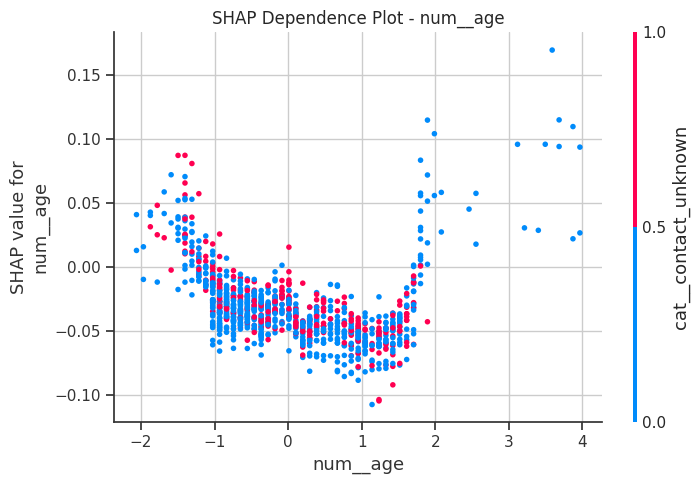

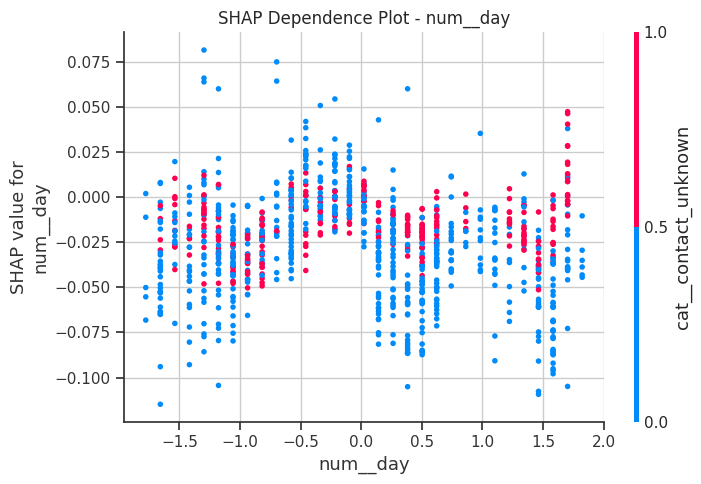

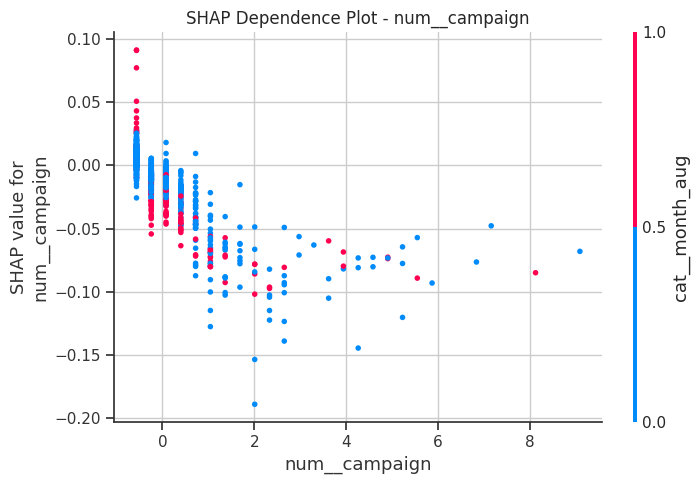

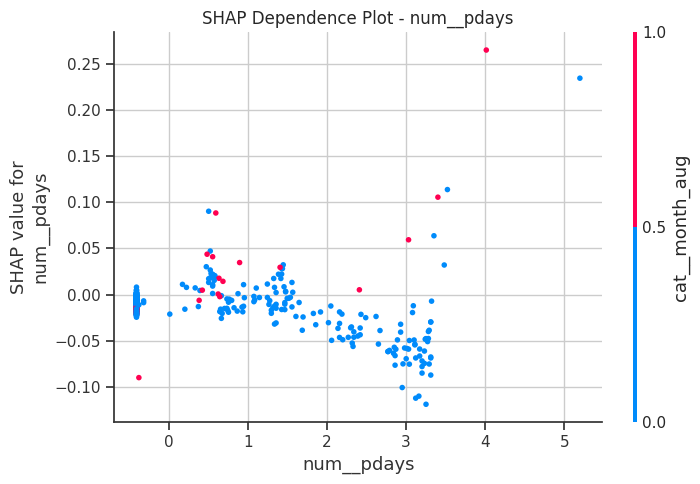

In [ ]:
# SHAP Dependence Analysis for the most important numerical features

numerical_features = [
    "num__balance",
    "num__age",
    "num__day",
    "num__campaign",
    "num__pdays"
]

for feature in numerical_features:

    if feature in feature_names:
        feature_idx = list(feature_names).index(feature)

        shap.dependence_plot(
            feature_idx,
            shap_values_positive,
            X_shap,
            feature_names=feature_names,
            show=False
        )

        plt.title(f"SHAP Dependence Plot - {feature}")
        plt.tight_layout()
        plt.show()

In [ ]:
numerical_features = [
    "num__balance",
    "num__age",
    "num__day",
    "num__campaign",
    "num__pdays"
]

dependence_results = []

for feature in numerical_features:

    if feature not in feature_names:
        continue

    idx = list(feature_names).index(feature)

    feature_values = X_shap[:, idx]
    feature_shap = shap_values_positive[:, idx]

    # Correlation between feature value and SHAP value
    correlation = np.corrcoef(
        feature_values,
        feature_shap
    )[0, 1]

    dependence_results.append({
        "Feature": feature,
        "Correlation_Feature_SHAP": correlation,
        "Mean_SHAP": feature_shap.mean(),
        "Mean_Abs_SHAP": np.abs(feature_shap).mean(),
        "Min_SHAP": feature_shap.min(),
        "Max_SHAP": feature_shap.max()
    })

dependence_df = pd.DataFrame(dependence_results)

dependence_df.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

,Feature,Correlation_Feature_SHAP,Mean_SHAP,Mean_Abs_SHAP,Min_SHAP,Max_SHAP
0,num__balance,0.340976,-0.047390,0.052035,-0.174373,0.074011
1,num__age,-0.195599,-0.030608,0.038642,-0.107838,0.169327
2,num__day,-0.121343,-0.024995,0.029490,-0.114814,0.081353
3,num__campaign,-0.755212,-0.014282,0.020855,-0.188799,0.091189
4,num__pdays,-0.229234,-0.009953,0.013660,-0.118506,0.264630


## 20. Error Analysis

This section analyzes the final model's prediction errors on the test set, with a particular focus on false positives and false negatives.

The goal is to understand where the model makes mistakes and evaluate the practical trade-off between identifying potential subscribers and avoiding unnecessary marketing efforts.

### 20.1 Test Set Predictions

Generate final test-set predictions using the selected decision threshold of 0.44.

In [ ]:
# Generate final test probabilities
y_test_proba = final_model.predict_proba(X_test)[:, 1]

# Apply the selected threshold
final_threshold = 0.44

y_test_pred = (
    y_test_proba >= final_threshold
).astype(int)

print("Test predictions generated successfully.")
print(f"Decision Threshold: {final_threshold}")

Test predictions generated successfully.
Decision Threshold: 0.44


### 20.2 Confusion Matrix Analysis

Break down the test predictions into True Positives, True Negatives, False Positives, and False Negatives.

In [ ]:
from sklearn.metrics import confusion_matrix

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_test_pred
).ravel()

print("Confusion Matrix Components")
print("-" * 40)
print(f"True Negatives  (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
print(f"True Positives  (TP): {tp}")

Confusion Matrix Components
----------------------------------------
True Negatives  (TN): 5415
False Positives (FP): 574
False Negatives (FN): 363
True Positives  (TP): 430


### 20.3 Prediction Error Distribution

Analyze the distribution of correct and incorrect predictions across the test set.

In [ ]:
# Create error analysis dataframe
error_analysis = pd.DataFrame({
    "Actual": y_test,
    "Predicted": y_test_pred,
    "Probability": y_test_proba
})

# Classify each prediction
error_analysis["Prediction_Type"] = np.select(
    [
        (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 1),
        (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 0),
        (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 1),
        (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 0)
    ],
    [
        "True Positive",
        "True Negative",
        "False Positive",
        "False Negative"
    ],
    default="Unknown"
)

print("Prediction Error Distribution")
print("-" * 45)

print(
    error_analysis["Prediction_Type"].value_counts()
)

Prediction Error Distribution
---------------------------------------------
Prediction_Type
True Negative     5415
False Positive     574
True Positive      430
False Negative     363
Name: count, dtype: int64


### 20.4 False Negative Analysis

False negatives represent customers who were actually interested in the product but were predicted as non-subscribers.

These errors are particularly important from a marketing perspective because they may represent missed opportunities.

In [ ]:
false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
].copy()

print(f"Number of False Negatives: {len(false_negatives)}")

false_negatives.head()

Number of False Negatives: 363


,Actual,Predicted,Probability,Prediction_Type
4136,1,0,0.038719,False Negative
11781,1,0,0.145059,False Negative
38012,1,0,0.119173,False Negative
35306,1,0,0.429983,False Negative
10948,1,0,0.081760,False Negative


In [ ]:
print("False Negative Probability Statistics")
print("-" * 45)

print(
    false_negatives["Probability"].describe()
)

False Negative Probability Statistics
---------------------------------------------
count    363.000000
mean       0.207120
std        0.109094
min        0.010804
25%        0.115511
50%        0.196296
75%        0.286188
max        0.439496
Name: Probability, dtype: float64


### 20.5 False Positive Analysis

False positives represent customers predicted as potential subscribers who ultimately did not subscribe.

These errors may lead to unnecessary marketing efforts and additional campaign costs.

In [ ]:
false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
].copy()

print(f"Number of False Positives: {len(false_positives)}")

false_positives.head()

Number of False Positives: 574


,Actual,Predicted,Probability,Prediction_Type
32009,0,1,0.801716,False Positive
44897,0,1,0.538351,False Positive
27338,0,1,0.620400,False Positive
41964,0,1,0.776772,False Positive
38584,0,1,0.566323,False Positive


In [ ]:
print("False Positive Probability Statistics")
print("-" * 45)

print(
    false_positives["Probability"].describe()
)

False Positive Probability Statistics
---------------------------------------------
count    574.000000
mean       0.637455
std        0.140098
min        0.440541
25%        0.510892
50%        0.618246
75%        0.755607
max        0.950294
Name: Probability, dtype: float64


### 20.6 Error Rates

Calculate the false positive rate and false negative rate to quantify the model's error behavior.

In [ ]:
false_positive_rate = fp / (fp + tn)
false_negative_rate = fn / (fn + tp)

print("Error Rate Analysis")
print("-" * 40)
print(f"False Positive Rate: {false_positive_rate:.4f}")
print(f"False Negative Rate: {false_negative_rate:.4f}")

Error Rate Analysis
----------------------------------------
False Positive Rate: 0.0958
False Negative Rate: 0.4578


The final model provides a useful ranking of potential subscribers and achieves a test F1-score of 47.86%, with 54.22% recall at the selected threshold.

In [ ]:
print(type(best_rf))
print(best_rf)

<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'balance', 'day',
                                                   'campaign', 'pdays',
                                                   'previous']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('enco

## 21. Final Model Saving

The final preprocessing pipeline and tuned Random Forest model are saved together to ensure consistent data preprocessing during future inference and deployment.

The selected decision threshold of 0.44 is also stored as part of the model configuration.

In [ ]:
import joblib
import os

# Final model and decision threshold
final_model = best_rf
final_threshold = 0.44

# Save model
model_path = "bank_marketing_final_model.joblib"
joblib.dump(final_model, model_path)

# Save threshold
threshold_path = "bank_marketing_threshold.joblib"
joblib.dump(final_threshold, threshold_path)

print("Final model saved successfully.")
print(f"Model path     : {model_path}")
print(f"Threshold path : {threshold_path}")
print(f"Threshold      : {final_threshold}")

Final model saved successfully.
Model path     : bank_marketing_final_model.joblib
Threshold path : bank_marketing_threshold.joblib
Threshold      : 0.44


### 21.1 Model Reload and Verification

Reload the saved model and verify that it produces the same predictions as the original final model.

In [ ]:
# Reload saved model and threshold
loaded_model = joblib.load(model_path)
loaded_threshold = joblib.load(threshold_path)

# Generate predictions using the reloaded model
y_test_proba_loaded = loaded_model.predict_proba(X_test)[:, 1]

y_test_pred_loaded = (
    y_test_proba_loaded >= loaded_threshold
).astype(int)

# Verify predictions
predictions_match = np.array_equal(
    y_test_pred,
    y_test_pred_loaded
)

print("Model Reload Verification")
print("-" * 40)
print(f"Loaded Threshold : {loaded_threshold}")
print(f"Predictions Match: {predictions_match}")

Model Reload Verification
----------------------------------------
Loaded Threshold : 0.44
Predictions Match: True


In [ ]:
model_size_mb = os.path.getsize(model_path) / (1024 ** 2)

print(f"Model Size: {model_size_mb:.2f} MB")

Model Size: 104.49 MB


### 21.2 Inference on a New Customer

Demonstrate how the saved pipeline can generate a subscription prediction directly from raw customer information.

In [ ]:
# Example new customer
new_customer = pd.DataFrame([{
    "age": 35,
    "job": "management",
    "marital": "single",
    "education": "tertiary",
    "default": "no",
    "balance": 1500,
    "housing": "yes",
    "loan": "no",
    "contact": "cellular",
    "day": 15,
    "month": "aug",
    "duration": 300,
    "campaign": 1,
    "pdays": -1,
    "previous": 0,
    "poutcome": "unknown"
}])

# Predict probability
prediction_probability = loaded_model.predict_proba(
    new_customer
)[:, 1][0]

# Apply final threshold
prediction = int(
    prediction_probability >= loaded_threshold
)

print("New Customer Prediction")
print("-" * 40)
print(f"Subscription Probability: {prediction_probability:.4f}")
print(f"Decision Threshold       : {loaded_threshold:.2f}")
print(
    f"Prediction               : "
    f"{'Subscription' if prediction == 1 else 'No Subscription'}"
)

New Customer Prediction
----------------------------------------
Subscription Probability: 0.3580
Decision Threshold       : 0.44
Prediction               : No Subscription


## 22. Final Business Insights

The final model and SHAP analysis provide several actionable insights for improving the efficiency of bank marketing campaigns.

The model should be used as a decision-support and customer-prioritization system rather than as a perfect predictor of customer behavior.

### Key Business Insights

1. **Previous campaign outcome is highly informative.**
   Customers with a successful previous campaign outcome showed a substantially higher subscription rate.

2. **Contact method is an important predictor.**
   Customers with unknown contact information had a considerably lower subscription rate compared with customers contacted through cellular or telephone channels.

3. **Campaign frequency matters.**
   The SHAP analysis showed a strong negative relationship between the number of campaign contacts (`campaign`) and the model contribution toward subscription.

4. **Customer balance and age contribute meaningfully to model decisions.**
   These numerical variables were among the most influential features according to mean absolute SHAP values.

5. **Month has a noticeable effect on subscription behavior.**
   Subscription rates varied substantially across months, indicating seasonal patterns in campaign effectiveness.

6. **The selected threshold prioritizes subscriber detection.**
   A threshold of 0.44 was selected to improve the balance between precision and recall compared with the default 0.50 threshold.

### Final Model Performance

The tuned Random Forest was selected as the final model based on its validation F1-score and overall ability to identify potential subscribers under class imbalance.

**Final Configuration:**

- Model: Tuned Random Forest
- Number of Trees: 527
- Class Weight: `balanced_subsample`
- Max Features: 0.7
- Minimum Samples per Leaf: 7
- Minimum Samples per Split: 10
- Decision Threshold: 0.44

**Test Performance:**

- Accuracy: 86.18%
- Precision: 42.83%
- Recall: 54.22%
- F1-score: 47.86%
- ROC-AUC: 78.32%

## 23. Conclusion

This project developed an end-to-end machine learning system for predicting whether bank customers are likely to subscribe to a term deposit.

The workflow covered data exploration, preprocessing, handling class imbalance, baseline modeling, Random Forest tuning, threshold optimization, model comparison, cross-validation, SHAP-based interpretability, error analysis, and final model serialization.

The tuned Random Forest achieved a test F1-score of **47.86%**, recall of **54.22%**, and ROC-AUC of **78.32%** at a decision threshold of **0.44**.

The model provides a practical mechanism for prioritizing customers for marketing campaigns. Rather than replacing business decisions, it can be used to rank customers according to their estimated likelihood of subscription, allowing marketing teams to allocate resources more efficiently.

The SHAP analysis further improves interpretability by identifying the features that most strongly influence model predictions, including contact method, balance, previous campaign outcome, age, campaign frequency, and housing status.